In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import xarray as xr
import matplotlib.pyplot as plt
import statsmodels.api as sm
import scipy.stats as stats
import matplotlib.cm as cm
import matplotlib.colors as mcolors

In [2]:
PATH = '/climca/people/glattus/Hindcast_data_ready'

def df_xr_prep(df):
    da=df.to_xarray()
    da=da.rename({'index':'year'})
    return da

##La Plata
#SON
hind_SON_LaPlata_xr=xr.open_dataset(PATH+'/Target_vars_LP_SON.nc')

#DJF
hind_DJF_LaPlata_xr=xr.open_dataset(PATH+'/Target_vars_LP_DJF.nc')

##Andes
hind_SON_Andes_xr=xr.open_dataset(PATH+'/Target_vars_Andes_SON.nc')
hind_DJF_Andes_xr=xr.open_dataset(PATH+'/Target_vars_Andes_DJF.nc')

#spring
ocean_SON_xr=xr.open_dataset(PATH+'/ENSO_IOD_SON.nc').drop_vars('lead_block').rename({'nino34':'ENSO', 'iod_index':'IOD'})
SAM_SON_xr=xr.open_dataset(PATH+'/SAM_ready_SON.nc')
SPV_SON_xr=xr.open_dataset(PATH+'/SPV_SON.nc').drop_vars(['lead_block', 'pressure_level']).rename({'u':'SPV'})


ocean_DJF_xr=xr.open_dataset(PATH+'/ENSO_IOB_DJF.nc').drop_vars('lead_block').rename({'nino34':'ENSO'})
SAM_DJF_xr=xr.open_dataset(PATH+'/SAM_ready_DJF.nc')
VB_DJF_xr=xr.open_dataset(PATH+'/VB_DOY_combined.nc').rename({'VB_DOY':'VB'})

display(VB_DJF_xr)

<xarray.Dataset> Size: 617kB
Dimensions:                  (sample: 19278)
Coordinates:
    init_month               (sample) int64 154kB ...
    forecast_reference_time  (sample) datetime64[ns] 154kB ...
    number                   (sample) int64 154kB ...
Dimensions without coordinates: sample
Data variables:
    VB                       (sample) float64 154kB ...

In [3]:
#function for excluding ssw years
def exclude_years(ds, years_list=[82,2019]):
    years = ds.forecast_reference_time.dt.year.compute()

    keep = ~years.isin(years_list)

    return ds.isel(sample=keep)

def align_hindcast_arrays(
    array_list,
    years_list,
    names=None,
    sample_coords=None,
    reference=0,
    verbose=True
):
    """
    Check and align xarray Datasets/DataArrays containing hindcast samples.

    Samples are identified by a combination of coordinates, by default:

        number
        init_month
        season
        forecast_reference_time

    The function:
      1. checks dimensions and required coordinates
      2. checks coordinate equality
      3. checks whether all datasets contain the same sample identities
      4. detects ordering differences
      5. reorders all datasets to the reference dataset's sample order
      6. verifies the final alignment

    Parameters
    ----------
    array_list : list
        List of xarray Dataset/DataArray objects.

    names : list, optional
        Names for diagnostic output.

    sample_coords : list, optional
        Coordinates defining a unique hindcast sample.

    reference : int
        Index of the dataset whose sample ordering is used
        as the reference.

    verbose : bool
        Print diagnostics.

    Returns
    -------
    aligned_arrays : list
        Aligned xarray objects.
    """

    # ---------------------------------------------------------
    # 1. Defaults
    # ---------------------------------------------------------

    if sample_coords is None:
        sample_coords = [
            "number",
            "init_month",
            "season",
            "forecast_reference_time"
        ]

    n_arrays = len(array_list)

    if names is None:
        names = [
            f"array_{i}"
            for i in range(n_arrays)
        ]

    if len(names) != n_arrays:
        raise ValueError(
            "names must have the same length as array_list"
        )

    if reference < 0 or reference >= n_arrays:
        raise ValueError(
            "reference must be a valid array index"
        )

    # ---------------------------------------------------------
    # 2. Basic checks
    # ---------------------------------------------------------

    if verbose:
        print("=" * 70)
        print("BASIC STRUCTURE")
        print("=" * 70)

    for name, arr in zip(names, array_list):

        if not isinstance(
            arr,
            (xr.Dataset, xr.DataArray)
        ):
            raise TypeError(
                f"{name} is not an xarray Dataset/DataArray"
            )

        if "sample" not in arr.dims:
            raise ValueError(
                f"{name} does not contain a 'sample' dimension"
            )

        print(
            f"{name:15s} "
            f"sample size = {arr.sizes['sample']}"
        )

    # ---------------------------------------------------------
    # 3. Check sample sizes
    # ---------------------------------------------------------

    sample_sizes = [
        arr.sizes["sample"]
        for arr in array_list
    ]

    if len(set(sample_sizes)) != 1:

        raise ValueError(
            "Datasets have different sample sizes:\n"
            + "\n".join(
                f"{name}: {size}"
                for name, size in zip(
                    names,
                    sample_sizes
                )
            )
        )

    n_samples = sample_sizes[0]

    # ---------------------------------------------------------
    # 4. Check sample coordinates
    # ---------------------------------------------------------

    if verbose:
        print("\n" + "=" * 70)
        print("CHECKING SAMPLE COORDINATES")
        print("=" * 70)

    for name, arr in zip(names, array_list):

        for coord in sample_coords:

            if coord not in arr.coords:

                raise ValueError(
                    f"{name} is missing coordinate "
                    f"{coord!r}"
                )

            if arr[coord].dims != ("sample",):

                raise ValueError(
                    f"{name}[{coord!r}] has dimensions "
                    f"{arr[coord].dims}, expected ('sample',)"
                )

        print(
            f"{name:15s}: all coordinates present"
        )

    # ---------------------------------------------------------
    # 5. Construct sample identities
    # ---------------------------------------------------------

    if verbose:
        print("\n" + "=" * 70)
        print("CONSTRUCTING SAMPLE IDENTITIES")
        print("=" * 70)

    identities = []

    for name, arr in zip(names, array_list):

        identity = pd.MultiIndex.from_arrays(
            [
                arr[coord].values
                for coord in sample_coords
            ],
            names=sample_coords
        )

        identities.append(identity)

        n_unique = identity.nunique()

        print(
            f"{name:15s}: "
            f"{n_unique} unique / "
            f"{n_samples} total"
        )

        if identity.has_duplicates:

            raise ValueError(
                f"{name} contains duplicate "
                f"sample identities."
            )

    # ---------------------------------------------------------
    # 6. Compare coordinate arrays position-by-position
    # ---------------------------------------------------------

    if verbose:
        print("\n" + "=" * 70)
        print("POSITIONAL COMPARISON")
        print("=" * 70)

    ref_arr = array_list[reference]
    ref_name = names[reference]

    for coord in sample_coords:

        print(f"\n{coord}")

        for i, arr in enumerate(array_list):

            if i == reference:
                continue

            same = np.array_equal(
                ref_arr[coord].values,
                arr[coord].values
            )

            print(
                f"  {ref_name} == {names[i]}: {same}"
            )

    # ---------------------------------------------------------
    # 7. Compare sample sets
    # ---------------------------------------------------------

    if verbose:
        print("\n" + "=" * 70)
        print("SAMPLE SET COMPARISON")
        print("=" * 70)

    reference_identity = identities[reference]

    reference_set = set(reference_identity)

    for i, identity in enumerate(identities):

        if i == reference:
            continue

        current_set = set(identity)

        only_reference = (
            reference_set - current_set
        )

        only_current = (
            current_set - reference_set
        )

        same_set = (
            len(only_reference) == 0
            and len(only_current) == 0
        )

        print(
            f"\n{ref_name} vs {names[i]}"
        )

        print(
            f"Same sample set: {same_set}"
        )

        print(
            f"Only {ref_name}: "
            f"{len(only_reference)}"
        )

        print(
            f"Only {names[i]}: "
            f"{len(only_current)}"
        )

        if not same_set:

            print("\nExample samples only in reference:")

            for item in list(only_reference)[:5]:
                print(item)

            print(
                "\nExample samples only in current:"
            )

            for item in list(only_current)[:5]:
                print(item)

            raise ValueError(
                f"{names[i]} does not contain "
                f"the same hindcast samples as "
                f"{ref_name}."
            )

    print(
        "\nAll datasets contain exactly the "
        "same sample identities."
    )

    # ---------------------------------------------------------
    # 8. Reorder datasets to reference ordering
    # ---------------------------------------------------------

    if verbose:
        print("\n" + "=" * 70)
        print("REORDERING TO REFERENCE SAMPLE ORDER")
        print("=" * 70)

    aligned_arrays = []

    for i, (name, arr, identity) in enumerate(
        zip(names, array_list, identities)
    ):

        # -----------------------------------------------------
        # Find the position of every reference sample
        # in this dataset.
        # -----------------------------------------------------

        position_lookup = {
            sample_identity: position
            for position, sample_identity
            in enumerate(identity)
        }

        try:

            reorder_index = np.array(
                [
                    position_lookup[sample_identity]
                    for sample_identity
                    in reference_identity
                ],
                dtype=int
            )

        except KeyError as e:

            raise ValueError(
                f"Could not find sample {e} "
                f"in {name}"
            )

        # Reorder along original sample dimension
        arr_aligned = arr.isel(
            sample=reorder_index
        )

        aligned_arrays.append(
            arr_aligned
        )

        # Check that ordering now matches
        new_identity = pd.MultiIndex.from_arrays(
            [
                arr_aligned[coord].values
                for coord in sample_coords
            ],
            names=sample_coords
        )

        if not new_identity.equals(
            reference_identity
        ):

            raise RuntimeError(
                f"Reordering failed for {name}"
            )

        print(
            f"{name:15s}: reordered successfully"
        )

    # ---------------------------------------------------------
    # 9. Final verification
    # ---------------------------------------------------------

    if verbose:
        print("\n" + "=" * 70)
        print("FINAL VERIFICATION")
        print("=" * 70)

    for coord in sample_coords:

        reference_values = (
            aligned_arrays[reference][coord].values
        )

        for i, arr in enumerate(aligned_arrays):

            same = np.array_equal(
                reference_values,
                arr[coord].values
            )

            if not same:

                raise RuntimeError(
                    f"Final alignment failed for "
                    f"{names[i]} coordinate {coord}"
                )

    print(
        "All sample-identifying coordinates "
        "are now identical."
    )

    print(
        f"All arrays contain {n_samples} "
        "aligned samples."
    )

    print("\nAlignment successful.")

    #exclude ssw years
    aligned_arrays=[exclude_years(arr_aligned, years_list=years_list) for arr_aligned in aligned_arrays]
    print(f"All arrays contain {aligned_arrays[0].sizes['sample']} aligned samples after excluding SSW years.")

    return aligned_arrays

In [4]:
all_aligned=align_hindcast_arrays([hind_SON_LaPlata_xr, hind_SON_Andes_xr,ocean_SON_xr, SPV_SON_xr, SAM_SON_xr], 
                                  names=['LaPlata','Andes','ocean', 'SPV', 'SAM'], years_list=[82,2019])
target_Andes_SON_xr=all_aligned[1]
target_LP_SON_xr=all_aligned[0]
drivers_aligned=all_aligned[2:]
drivers_SON_xr=xr.merge(drivers_aligned)

init_sel = np.intersect1d(
    np.unique(VB_DJF_xr.init_month.values),
    np.unique(hind_DJF_LaPlata_xr.init_month.values)
)
print(init_sel)

djf_list = [
    hind_DJF_LaPlata_xr.drop_vars(['lead_block', 'season']),
    hind_DJF_Andes_xr.drop_vars(['lead_block', 'season']),
    ocean_DJF_xr.drop_vars(['season']),
    VB_DJF_xr,
    SAM_DJF_xr.drop_vars([ 'season'])
]

djf_sel_list = [
    exclude_years(array.where(
        array.init_month.isin(init_sel),
        drop=True
    ), [82,83,2019,2020])
    for array in djf_list
]

def get_common_identity(arr):
    return pd.MultiIndex.from_arrays(
        [
            arr.number.values,
            arr.init_month.values,
            arr.forecast_reference_time.values
        ],
        names=[
            'number',
            'init_month',
            'forecast_reference_time'
        ]
    )

identities = [
    get_common_identity(arr)
    for arr in djf_sel_list
]

common_ids = identities[0]

for ids in identities[1:]:
    common_ids = common_ids.intersection(ids)

print("Number of common samples:", len(common_ids))

def add_sample_id(arr):
    return arr.assign_coords(
        sample_id=(
            "sample",
            [
                f"{n}_{t}"
                for n, t in zip(
                    arr.number.values,
                    arr.forecast_reference_time.values
                )
            ]
        )
    )

djf_sel_list = [
    add_sample_id(arr)
    for arr in djf_sel_list
]

common_ids = set(djf_sel_list[0].sample_id.values)

for arr in djf_sel_list[1:]:
    common_ids &= set(arr.sample_id.values)

print(len(common_ids))

common_ids = list(common_ids)

aligned = [
    arr.where(
        arr.sample_id.isin(common_ids),
        drop=True
    )
    for arr in djf_sel_list
]

target_Andes_DJF_xr=aligned[1]
target_LP_DJF_xr=aligned[0]
drivers_aligned_DJF=aligned[2:]
drivers_DJF_xr=xr.merge(drivers_aligned_DJF)

aligned_DJF_no_VB=align_hindcast_arrays([hind_DJF_LaPlata_xr, hind_DJF_Andes_xr, ocean_DJF_xr, SAM_DJF_xr], years_list=[83,2020])
target_Andes_DJF_xr_no_VB=aligned_DJF_no_VB[1]
target_LP_DJF_xr_no_VB=aligned_DJF_no_VB[0]
drivers_aligned_no_VB=aligned_DJF_no_VB[2:]
drivers_DJF_xr_no_VB=xr.merge(drivers_aligned_no_VB)

BASIC STRUCTURE
LaPlata         sample size = 34272
Andes           sample size = 34272
ocean           sample size = 34272
SPV             sample size = 34272
SAM             sample size = 34272

CHECKING SAMPLE COORDINATES
LaPlata        : all coordinates present
Andes          : all coordinates present
ocean          : all coordinates present
SPV            : all coordinates present
SAM            : all coordinates present

CONSTRUCTING SAMPLE IDENTITIES
LaPlata        : 34272 unique / 34272 total
Andes          : 34272 unique / 34272 total
ocean          : 34272 unique / 34272 total
SPV            : 34272 unique / 34272 total
SAM            : 34272 unique / 34272 total

POSITIONAL COMPARISON

number
  LaPlata == Andes: True
  LaPlata == ocean: True
  LaPlata == SPV: True
  LaPlata == SAM: True

init_month
  LaPlata == Andes: True
  LaPlata == ocean: True
  LaPlata == SPV: False
  LaPlata == SAM: True

season
  LaPlata == Andes: True
  LaPlata == ocean: True
  LaPlata == SPV: True
 

In [5]:
import sys
sys.path.insert(0, "../whole_period_effects")  # add Folder_2 path to search list

import Functions

from Functions_bootstrap import modify_driver_list

In [6]:
def bootstrap_regression(
    target_ds,
    driver_ds,
    target_var,
    driver_vars,
    n_boot=50,
    sample_size=None,
    add_intercept=True,
    seed=42,
    total_eff=False,
    yearwise=False
):

    # ------------------------------------------------------------
    # 1. Select first 25 ensemble members
    # ------------------------------------------------------------

    members = np.sort(np.unique(target_ds.number.values))
    members_mask = members[:25]

    target_ds = target_ds.where(
        target_ds.number.isin(members_mask),
        drop=True
    )

    driver_ds = driver_ds.where(
        driver_ds.number.isin(members_mask),
        drop=True
    )

    n_samples = target_ds.sizes["sample"]

    # ------------------------------------------------------------
    # 2. Years
    # ------------------------------------------------------------

    years_per_obs = target_ds.forecast_reference_time.dt.year.values
    years = np.unique(years_per_obs)

    if sample_size is None:
        sample_size = len(years)

    # ------------------------------------------------------------
    # 3. Convert everything to NumPy ONCE
    # ------------------------------------------------------------

    y_all = target_ds[target_var].values

    controls_dict = modify_driver_list(
        driver_vars,
        total_eff=total_eff
    )

    # ------------------------------------------------------------
    # 4. Generate bootstrap year indices ONCE
    # ------------------------------------------------------------

    rng = np.random.default_rng(seed)

    if yearwise==True:
        bootstrap_years = rng.choice(
        years,
        size=(n_boot, sample_size),
        replace=True
        )

        # Precompute indices belonging to each year
        year_indices = {
                year: np.flatnonzero(years_per_obs == year)
                for year in years
        }
        
        print(year_indices.keys())

    else:
        #get bootstrap indices before opening loop to ensure each driver regression has same samples
        bootstrap_indices = rng.choice(
                n_samples,
                size=(n_boot, sample_size),
                replace=True
            )
            

    # ------------------------------------------------------------
    # 5. Results
    # ------------------------------------------------------------

    results = []

    # ------------------------------------------------------------
    # 6. Loop over drivers
    # ------------------------------------------------------------

    for driver in driver_vars:

        controls = controls_dict[driver]

        if controls is None:
            regression_vars = [driver]
        else:
            regression_vars = [driver] + controls

        # Get driver data ONCE
        X_all = np.column_stack([
            driver_ds[var].values
            for var in regression_vars
        ])

        # --------------------------------------------------------
        # Bootstrap
        # --------------------------------------------------------

        for b in range(n_boot):

            if yearwise:
                # Build indices directly with NumPy
                idx = np.concatenate([
                year_indices[year]
                for year in bootstrap_years[b]
                ])

            else:
                idx = bootstrap_indices[b]

            X = X_all[idx]
            y = y_all[idx]

            # Remove NaNs
            valid = (
                np.isfinite(y)
                & np.all(np.isfinite(X), axis=1)
            )

            X = X[valid]
            y = y[valid]

            n_valid = len(y)

            n_predictors = X.shape[1]
            n_parameters = n_predictors + int(add_intercept)

            if n_valid <= n_parameters:
                continue

            # Add intercept
            if add_intercept:
                Xreg = np.column_stack([
                    np.ones(n_valid),
                    X
                ])
                focal_idx = 1
            else:
                Xreg = X
                focal_idx = 0

            # ----------------------------------------------------
            # Least squares
            # ----------------------------------------------------

            beta, residuals, rank, s = np.linalg.lstsq(
                Xreg,
                y,
                rcond=None
            )

            if rank < Xreg.shape[1]:
                continue

            # R²
            y_hat = Xreg @ beta

            ss_res = np.sum((y - y_hat) ** 2)
            ss_tot = np.sum((y - np.mean(y)) ** 2)

            r2 = (
                1.0 - ss_res / ss_tot
                if ss_tot > 0
                else np.nan
            )

            results.append({
                "bootstrap": b,
                "target": target_var,
                "drivers": "+".join(regression_vars),
                f"coef_{driver}": beta[focal_idx],
                "r2": r2,
                'Index':idx
            })

    return pd.DataFrame(results)



In [7]:
def plot_bootstrap_coefficients(results, driver_vars, title="Bootstrap regression coefficients", 
                                bins_num=100, era5_vals=None):
    'era5_vals must be a dict with driver names as in driver_vars and values from ERA5 regression'

    fsize=18
    lim_x=5.0
    ncols=len(driver_vars)

    global_max=max(
        np.max(np.abs(results[f"coef_{driver}"]))
        for driver in driver_vars
    )

    fig, axes = plt.subplots(
    ncols=ncols,
    figsize=(ncols * 6, 6),
    sharey=True,
    squeeze=False
    )

    axes = axes.ravel()

    for i, var in enumerate(driver_vars):
        n, bins, _=axes[i].hist(
            results[f"coef_{var}"],
            bins=bins_num #,
            #label=var
        )

        subplot_title=var

        mean = results[f"coef_{var}"].mean()
        std = results[f"coef_{var}"].std()

        #add CI
        lower = np.nanpercentile(results[f'coef_{var}'], 2.5)
        upper = np.nanpercentile(results[f'coef_{var}'], 97.5)

        significant = (lower > 0) or (upper < 0)

        axes[i].axvline(
                    mean,
                    linestyle="--", color='red', 
                    label=f'Mean: {mean:.2f}'
                )

        if era5_vals is not None:
            axes[i].axvline(era5_vals[var], color='black', label=f'ERA5: {era5_vals[var]:.2f}', linewidth=3)

        #axes[i].axvspan(xmin=mean-std, xmax=mean+std, alpha=.3, color='red', label='$\pm 1 \sigma$: '+str(round(std,2)))
        axes[i].axvspan(xmin=lower, xmax=upper, alpha=.3, color='red', label=f'95% CI: [{lower:.2f}, {upper:.2f}]')

        if significant:
            #or maybe add text to driver heading
            subplot_title+=' (significant)'
            # axes[i].text(
            #     0.8, 0.15,
            #     "Significant \n link",
            #     transform=axes[i].transAxes,
            #     ha="center",
            #     va="top",
            #     fontsize=18
            # )

        axes[i].set_xlabel(f"Reg coef of {var}", fontsize=fsize)
        axes[i].tick_params( axis="both",
                    which="major",
                    labelsize=fsize)
        axes[i].grid(alpha=.3)
        axes[i].legend(fontsize=fsize)
        #restrict x axis to some value
        if global_max>lim_x:
            subplot_title+=' (*)'

        else:
            lim_x=global_max
    
        axes[i].set_xlim(-lim_x,lim_x)
        axes[i].set_title(subplot_title, fontsize=fsize, fontweight='bold')

    axes[0].set_ylabel("Count", fontsize=fsize)
    fig.suptitle(title, fontsize=fsize+4, fontweight='heavy', y=1.1)
    fig.tight_layout()
    fig.savefig('Histograms/'+title.replace(" ", "_")+".jpg", dpi=300, bbox_inches='tight')
    plt.show()

In [8]:
#first mixing all
ENSO_precip_LP_SON_tot=bootstrap_regression(target_ds=target_LP_SON_xr, driver_ds=drivers_SON_xr, driver_vars=['ENSO'],
                                            target_var='tp', n_boot=10000, sample_size=200, total_eff=True, add_intercept=True)

#now yearwise
ENSO_precip_LP_SON_tot_yearwise=bootstrap_regression(target_ds=target_LP_SON_xr, driver_ds=drivers_SON_xr, driver_vars=['ENSO'],
                                            target_var='tp', n_boot=10000, sample_size=8, total_eff=True, yearwise=True, add_intercept=True)



dict_keys([np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2020), np.int64(2021), np.int64(2022)])


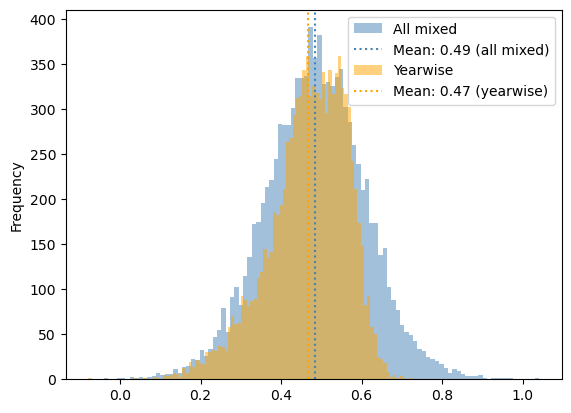

In [9]:
ENSO_precip_LP_SON_tot['coef_ENSO'].plot.hist(alpha=0.5, label='All mixed', color='steelblue', bins=100)
mean_all=np.mean(ENSO_precip_LP_SON_tot['coef_ENSO'])
plt.axvline(mean_all, linestyle='dotted', color='steelblue',
            label=f'Mean: {mean_all:.2f} (all mixed)')
ENSO_precip_LP_SON_tot_yearwise['coef_ENSO'].plot.hist(alpha=0.5, color='orange', label='Yearwise', bins=100)
mean=np.mean(ENSO_precip_LP_SON_tot_yearwise['coef_ENSO'])
plt.axvline(mean, linestyle='dotted', 
            label=f'Mean: {mean:.2f} (yearwise)', color='orange')
plt.legend()
plt.show()

In [10]:
from matplotlib.patches import Ellipse

In [11]:
def scatter_hist_visual(coef_array, target_ds, driver_ds, suptitle, driver, n=5):
    '''n= spacing number, number of bootstrap samples plotted
    'Coef_array must incude all the bootstrap reg coefs
    target_ds and drivers_ds must have already the accessed variable
    suptitle should include name of target and name of driver'''
    #choose n different sampes for now
    equal_spacing=np.linspace(np.min(coef_array[f'coef_{driver}']), 
                              np.max(coef_array[f'coef_{driver}']), n)
    print(equal_spacing)
    fsize=16
    cols=3
    colors = cm.rainbow(np.linspace(0, 1, n))
    fig, ax = plt.subplots(nrows=1, ncols=cols, figsize=(7*cols, 6))
    handles=[]
    labels=[]

    for i, val in enumerate(equal_spacing):
        mask= (coef_array[f'coef_{driver}']-val).abs().idxmin()
        #print(mask)
        selected=coef_array.loc[mask]

        sample_indices = np.asarray(selected["Index"], dtype=int)
        
        #Select the corresponding observations
        #important to select members here too!
        members = np.sort(np.unique(target_ds.number.values))
        members_mask = members[:25]

        target_plot = target_ds.where(
            target_ds.number.isin(members_mask), drop=True
        )

        drivers_plot = driver_ds.where(
            driver_ds.number.isin(members_mask), drop=True
        )

        drivers_sel = drivers_plot.isel(sample=sample_indices)
        target_sel = target_plot.isel(sample=sample_indices)
        # Flatten for plotting, if the selected arrays are multidimensional
        x = np.asarray(drivers_sel.values).ravel()
        y = np.asarray(target_sel.values).ravel()
        valid = np.isfinite(x) & np.isfinite(y)

        x_valid=x[valid]
        y_valid=y[valid]

        #handle_i=ax[0].scatter(
        #    x[valid],
        #    y[valid],
        #    alpha=0.6, color=colors[i])


        # Fit regression using valid observations
        Xreg = np.column_stack([
            np.ones(len(x[valid])),
            x[valid]
        ])

        beta, residuals, rank, s = np.linalg.lstsq(
            Xreg,
            y[valid],
            rcond=None
        )

        # Generate a smooth regression line
        x_line = np.linspace(x[valid].min(), x[valid].max(), 100)
        y_line = beta[0] + beta[1] * x_line
        
        ax[0].plot(
            x_line,
            y_line,
            label=f"Slope: {beta[1]:.2f}",
            color=colors[i]
        )

        # Points


        points = np.column_stack((x_valid, y_valid))
        center = points.mean(axis=0)
        centered = points - center

        # PCA
        cov = np.cov(centered, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(cov)

        order = np.argsort(eigenvalues)[::-1]
        eigenvectors = eigenvectors[:, order]

        # Project points into PCA coordinates
        projected = centered @ eigenvectors

        # Initial semi-axis lengths
        a = np.max(np.abs(projected[:, 0]))
        b = np.max(np.abs(projected[:, 1]))

        # Scale ellipse until all points are enclosed
        r = np.sqrt((projected[:, 0] / a)**2 +
                    (projected[:, 1] / b)**2)

        scale = np.max(r) * 1.03
        a *= scale
        b *= scale

        # Rotation angle of the first principal axis
        angle = np.degrees(
            np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
        )

        ellipse = Ellipse(
            xy=center,
            width=2 * a,
            height=2 * b,
            angle=angle,
            facecolor=colors[i],
            edgecolor=colors[i],
            alpha=0.2,
            linewidth=1.5
        )

        ax[0].add_patch(ellipse)

        handle_i=ellipse
        handles.append(handle_i)
        labels.append(f"β = {selected[f'coef_{driver}']:.2f}")

        ax[0].set_xlabel(f"Driver {driver}", fontsize=fsize)
        ax[0].set_ylabel("Target", fontsize=fsize)
        ax[0].grid(True, alpha=0.3)
        ax[0].axhline(y=0, color='grey')
        ax[0].axvline(x=0, color='grey')

        #Plot 2: Hist of sample distrib target
        ax[1].hist(target_sel, color=colors[i], alpha=.3, bins=15, histtype='step', linewidth=3)
        ax[1].set_ylabel('Count', fontsize=fsize)
        ax[1].set_xlabel('Target', fontsize=fsize)


        #Plot 3: Hist of sample distrib target
        ax[2].hist(drivers_sel, color=colors[i], alpha=.3, bins=15, histtype='step', linewidth=3)
        ax[2].set_ylabel('Count', fontsize=fsize)
        ax[2].set_xlabel(f'{driver}', fontsize=fsize)

        for i in range(cols):
            ax[i].tick_params(labelsize=fsize)

    #add 
    fig.legend(handles, labels, ncols=n, bbox_to_anchor=(0.5, -0.12), loc='lower center', fontsize=fsize+2)
    fig.suptitle(suptitle, fontweight='bold', fontsize=fsize+4)
    plt.tight_layout()
    plt.show()

[-0.0408889   0.22971356  0.50031601  0.77091846  1.04152091]


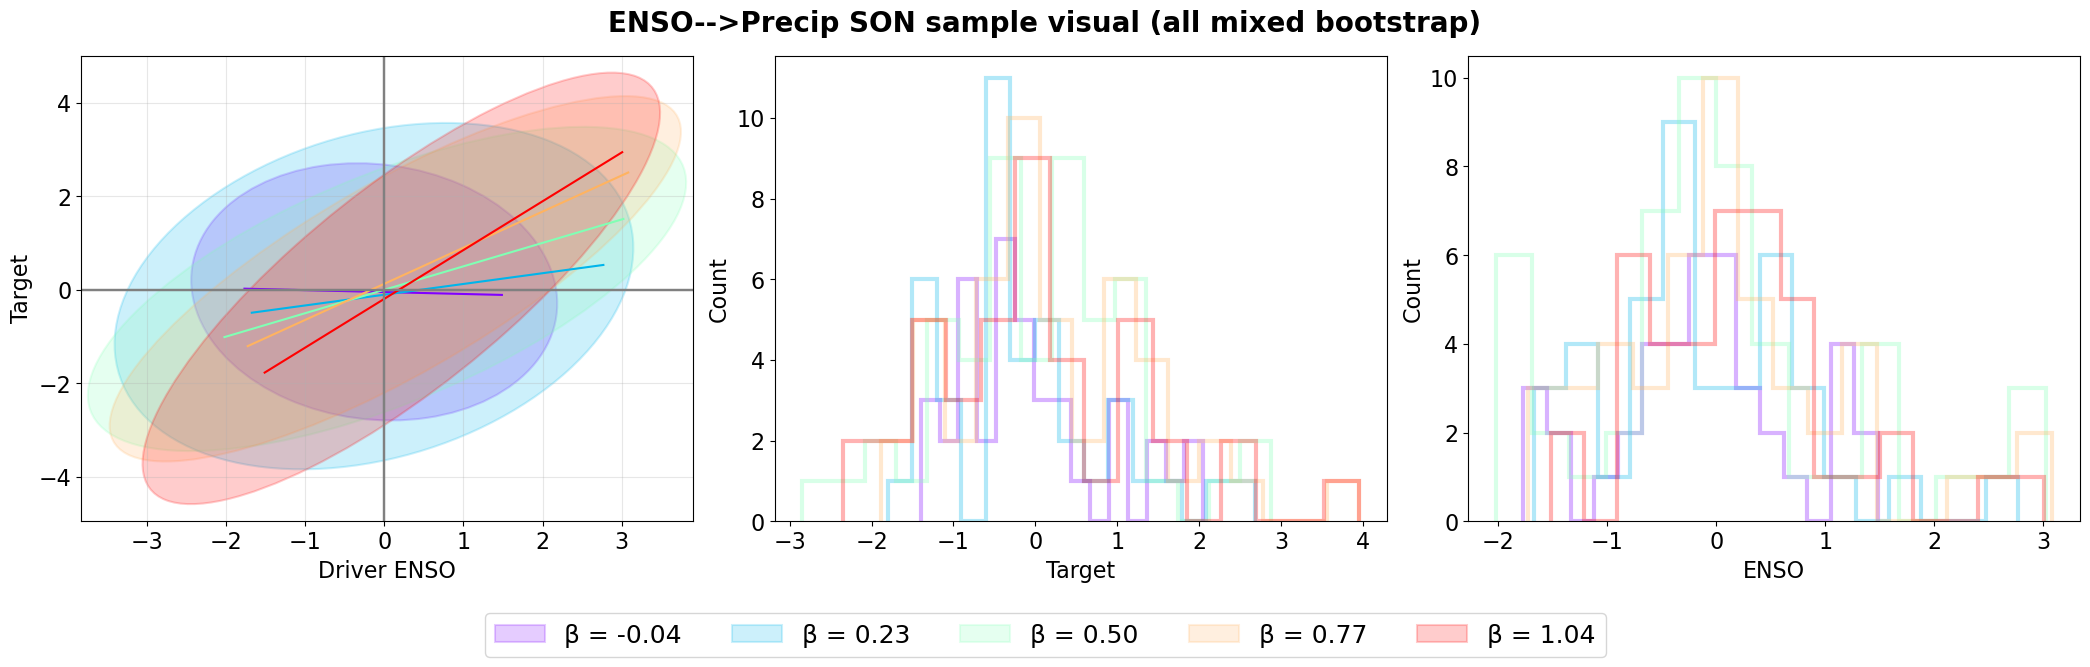

[-0.0787232   0.12255731  0.32383782  0.52511833  0.72639883]


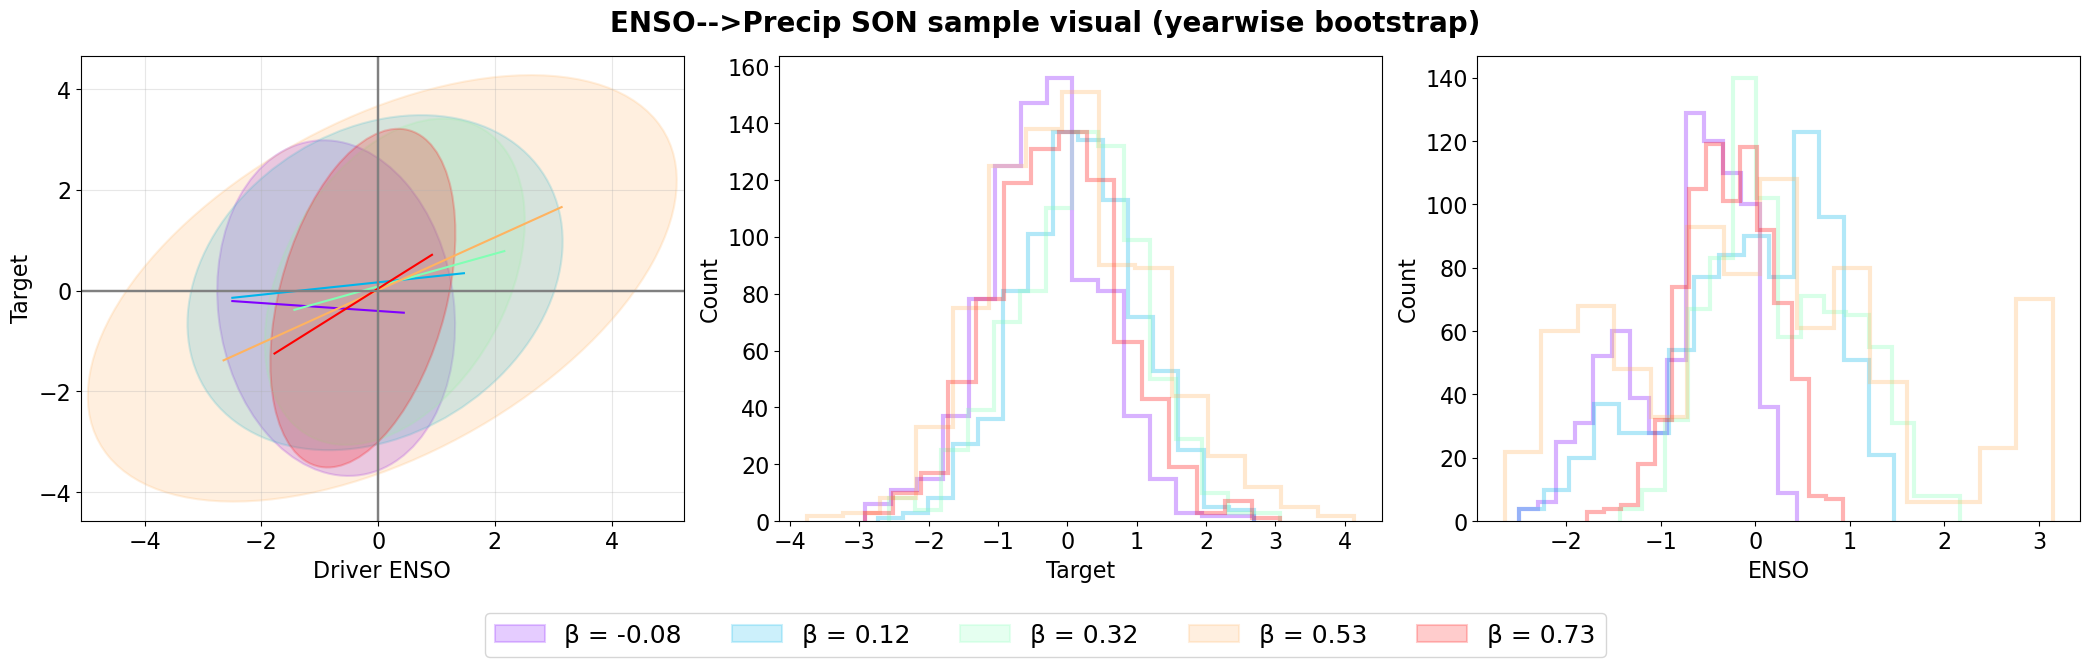

In [12]:
scatter_hist_visual(coef_array=ENSO_precip_LP_SON_tot, target_ds=target_LP_SON_xr['tp'], 
                    driver_ds=drivers_SON_xr['ENSO'], driver='ENSO', 
                    suptitle='ENSO-->Precip SON sample visual (all mixed bootstrap)')

scatter_hist_visual(coef_array=ENSO_precip_LP_SON_tot_yearwise, target_ds=target_LP_SON_xr['tp'], 
                    driver_ds=drivers_SON_xr['ENSO'], driver='ENSO', 
                    suptitle='ENSO-->Precip SON sample visual (yearwise bootstrap)')

Separate by init month

dict_keys([np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2020), np.int64(2021), np.int64(2022)])


[0.02035731 0.27150707 0.52265682 0.77380658 1.02495633]


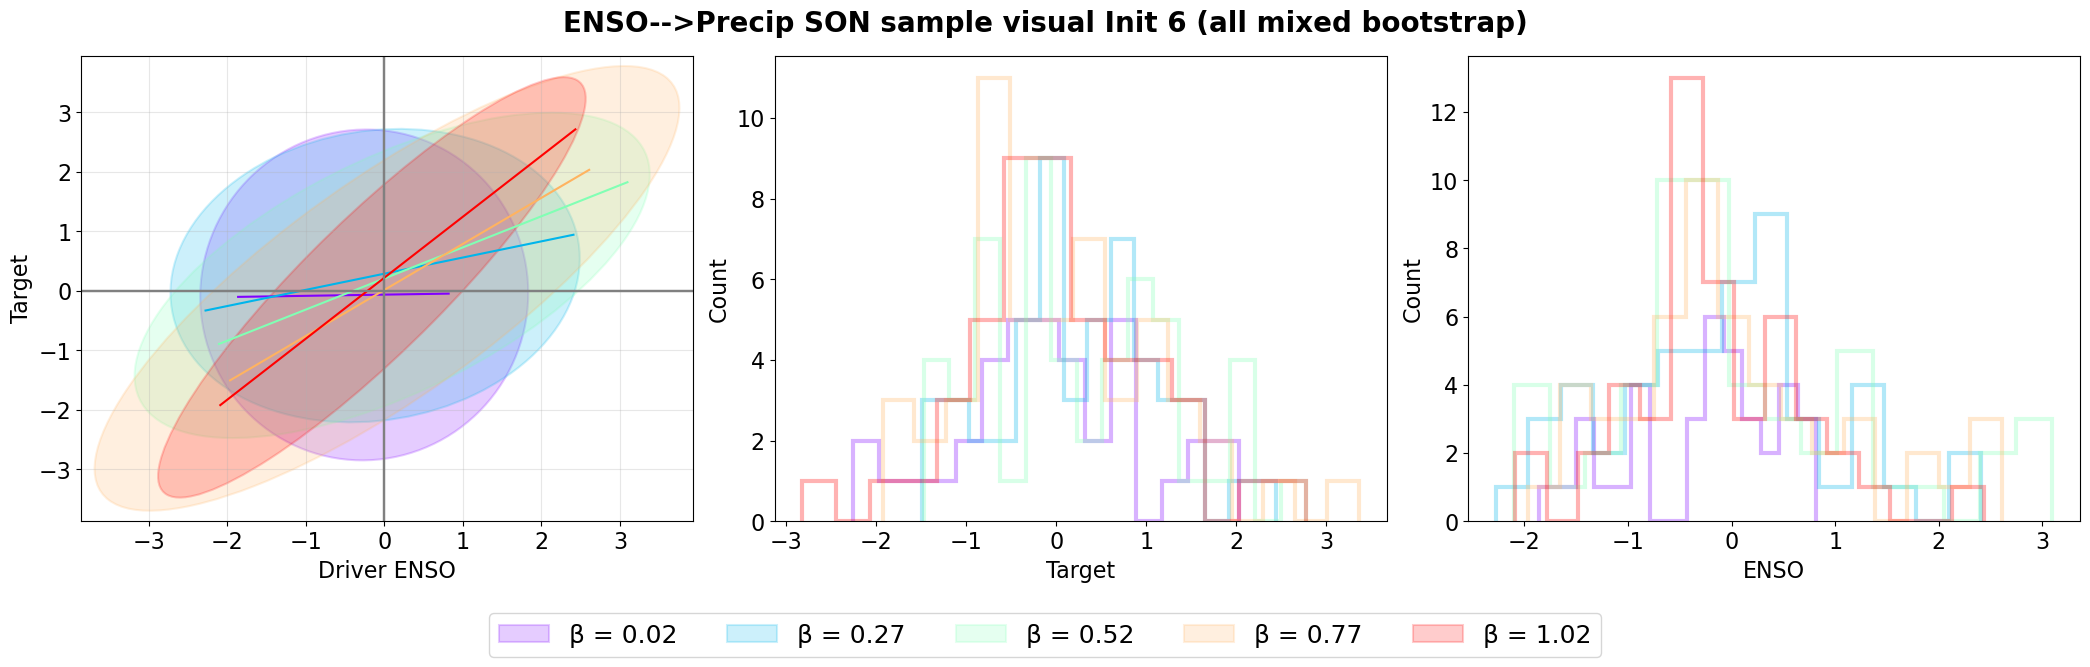

[0.04709188 0.27590304 0.50471421 0.73352538 0.96233654]


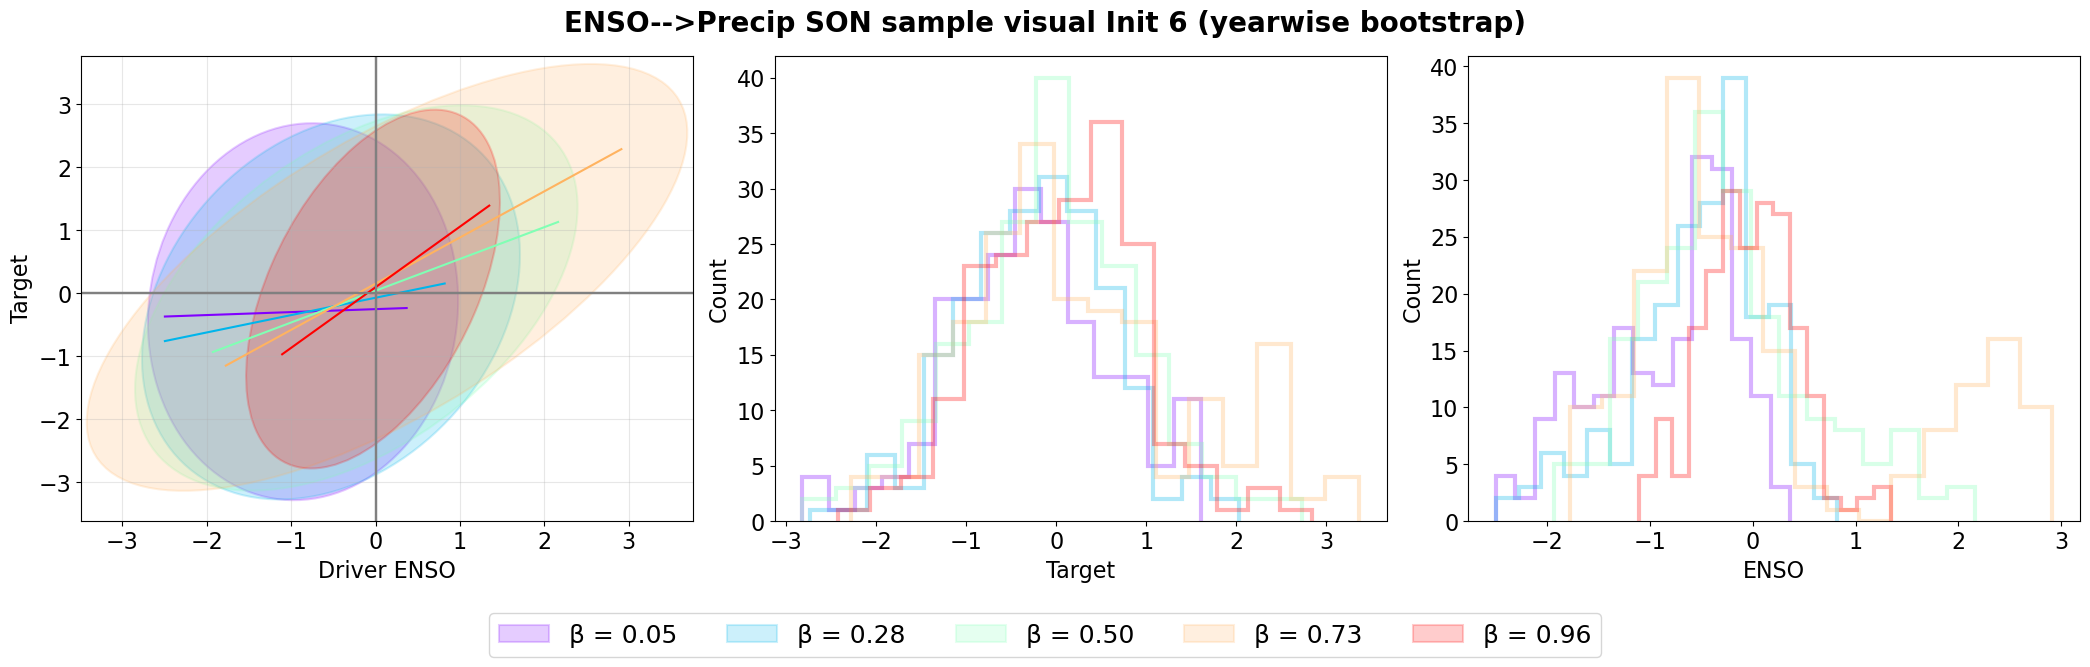

dict_keys([np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2020), np.int64(2021), np.int64(2022)])
[-0.09192923  0.20654403  0.50501729  0.80349054  1.1019638 ]


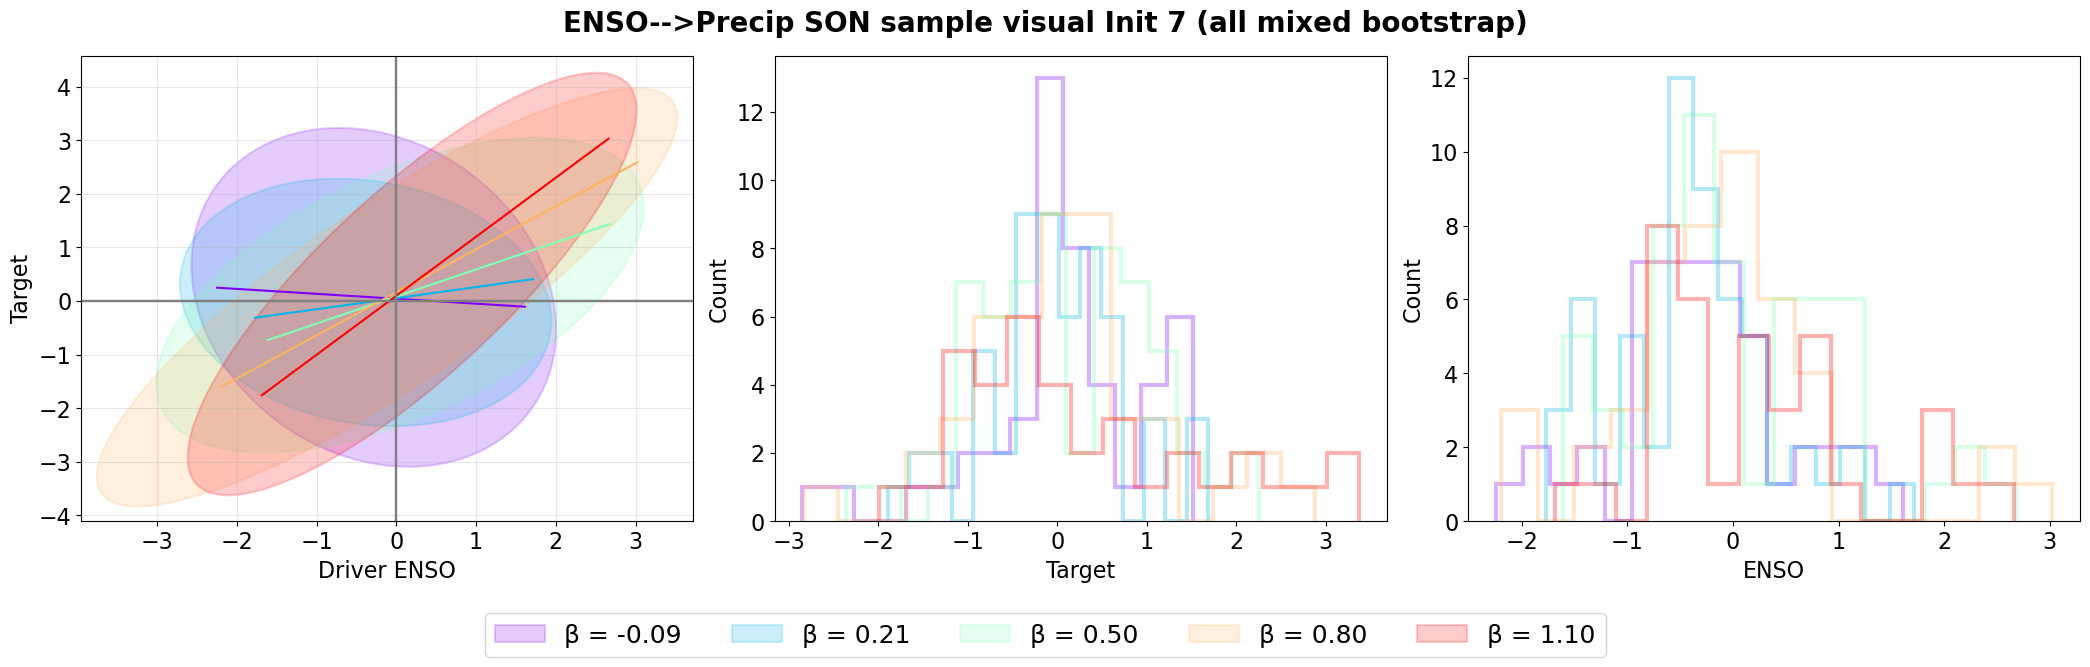

[-0.02096555  0.22105579  0.46307713  0.70509847  0.94711981]


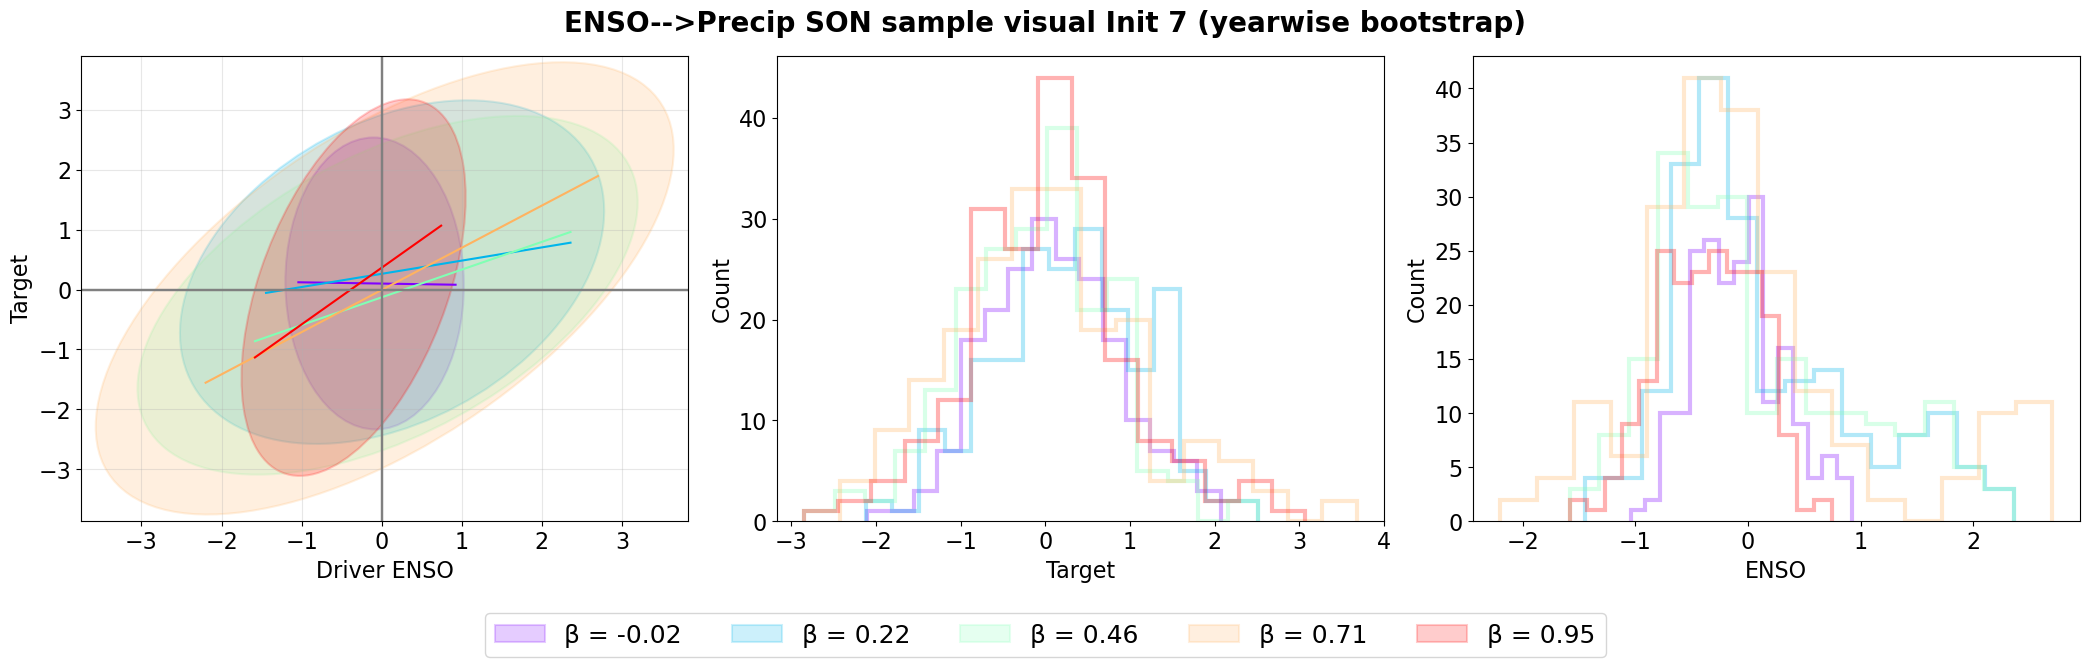

dict_keys([np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2020), np.int64(2021), np.int64(2022)])
[-0.16037205  0.11402736  0.38842677  0.66282617  0.93722558]


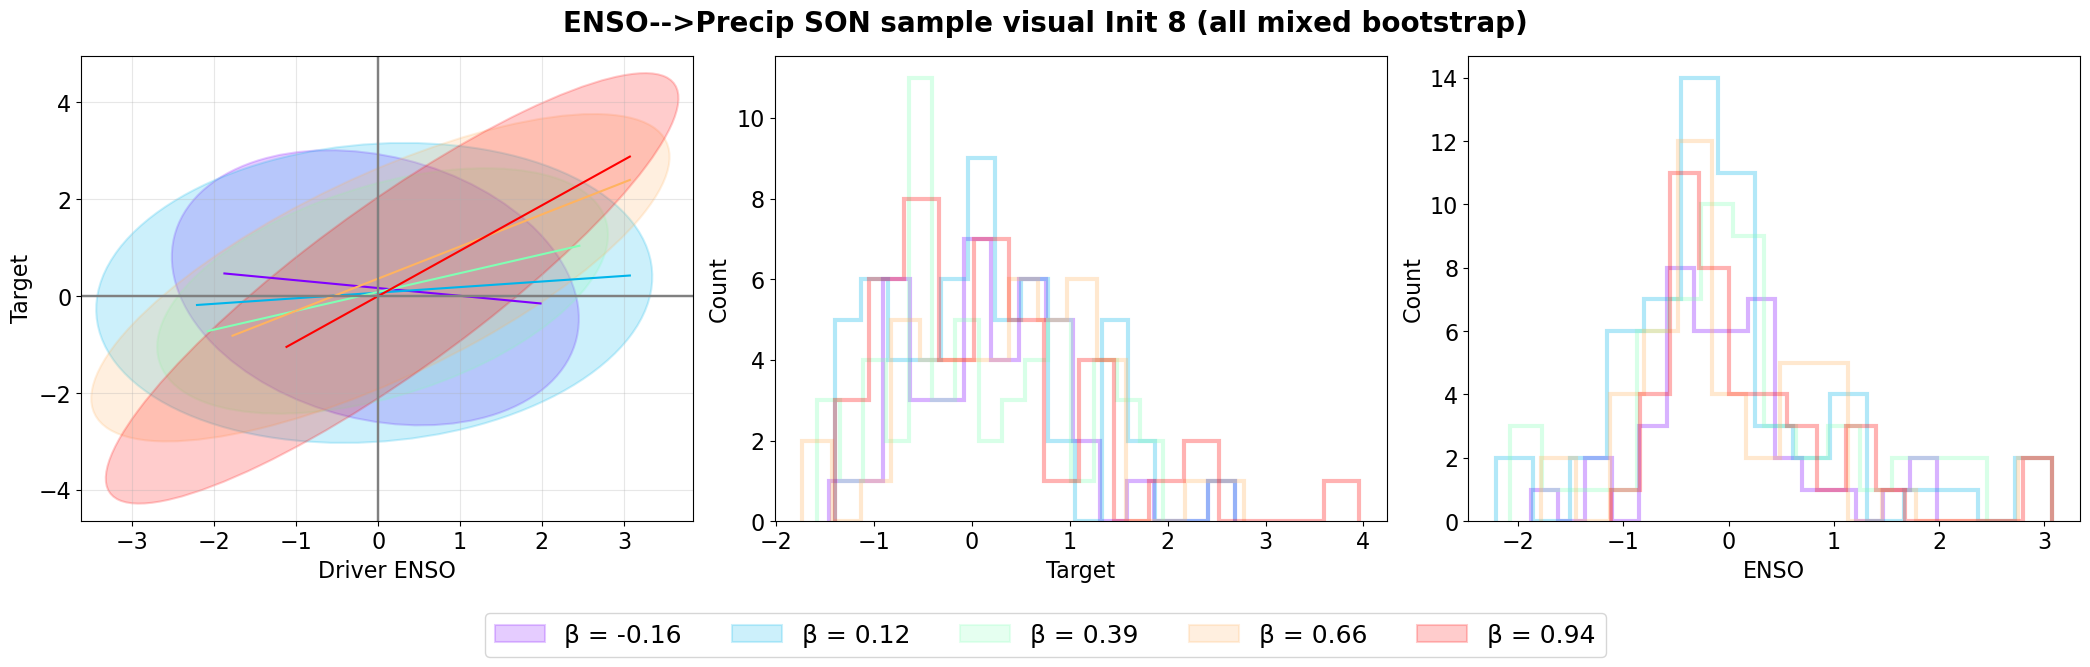

[-0.13933264  0.12189114  0.38311493  0.64433871  0.90556249]


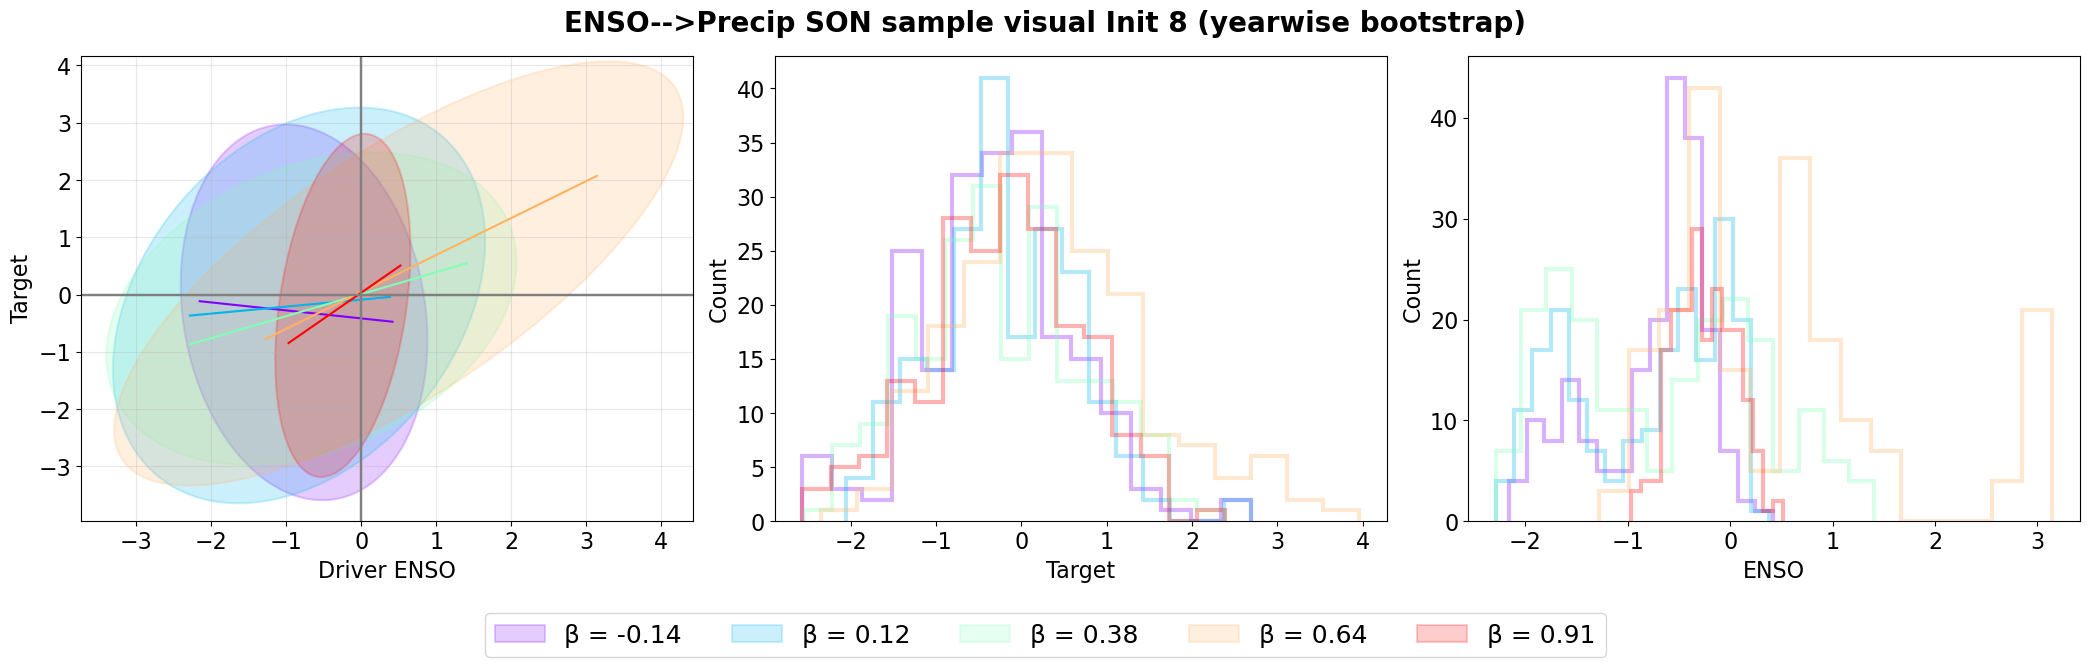

dict_keys([np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2020), np.int64(2021), np.int64(2022)])
[0.01154003 0.2634945  0.51544898 0.76740345 1.01935793]


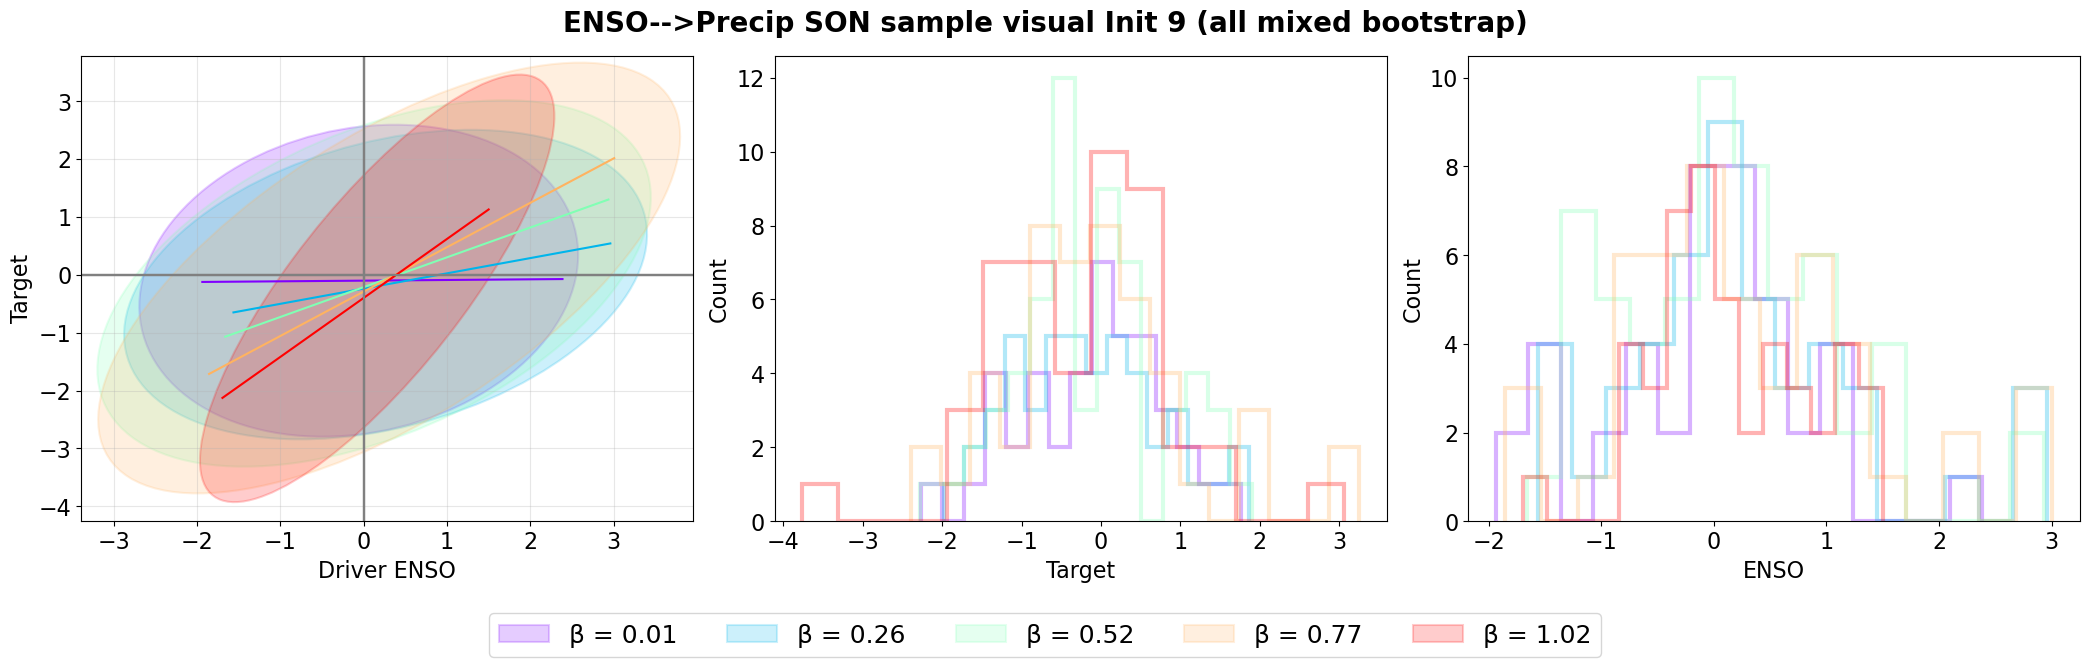

[-0.29605302  0.24226955  0.78059211  1.31891468  1.85723725]


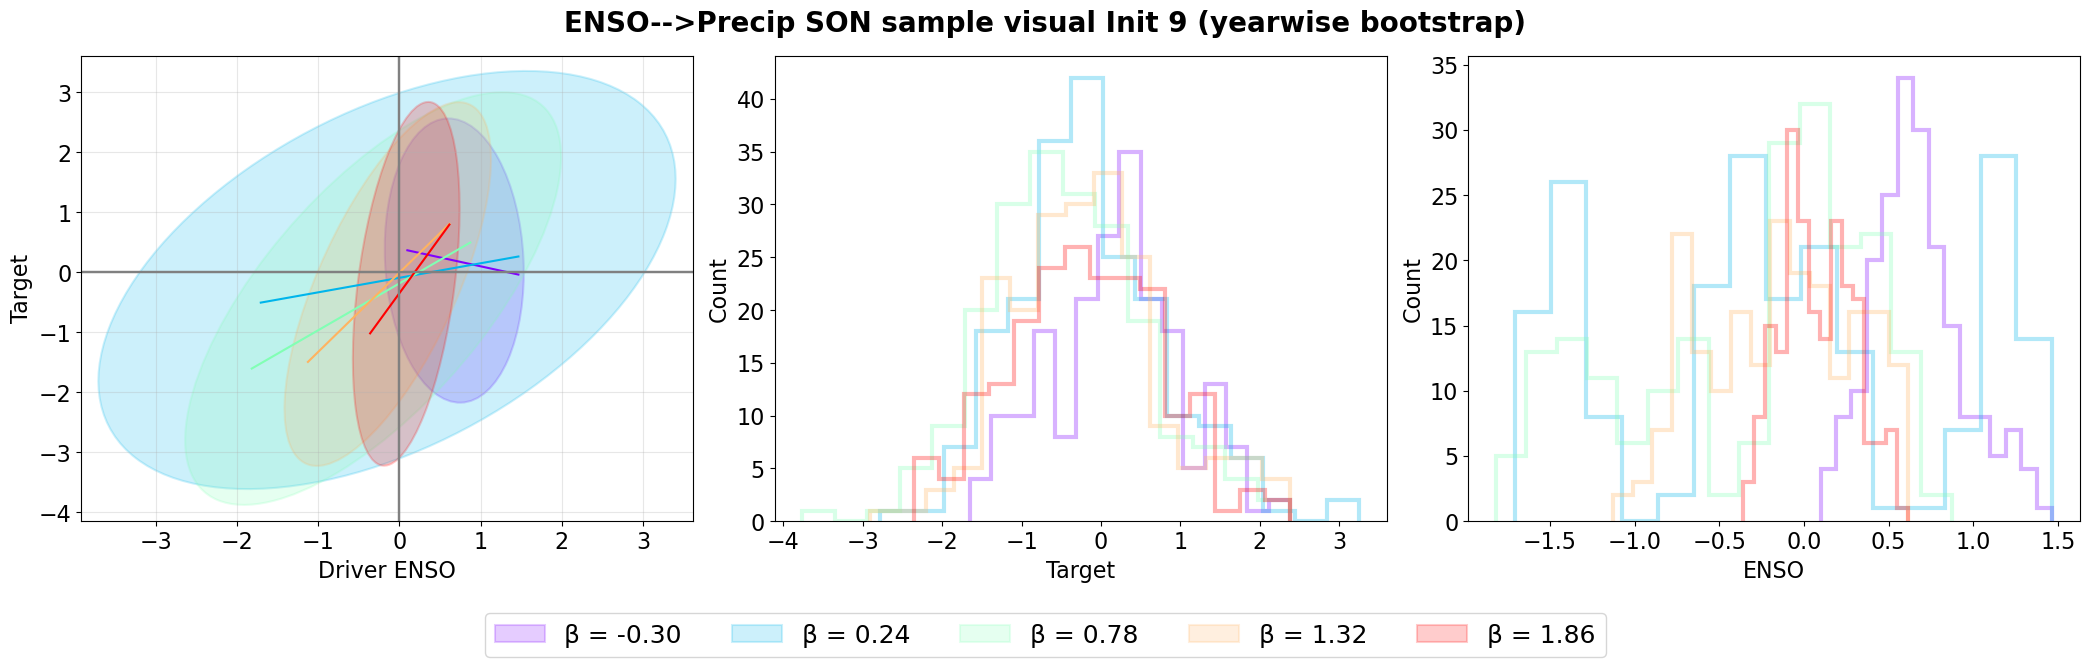

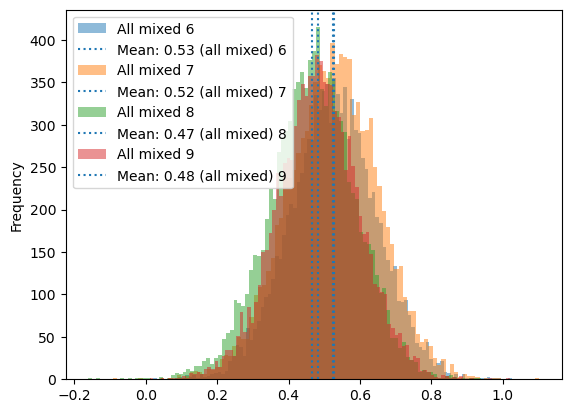

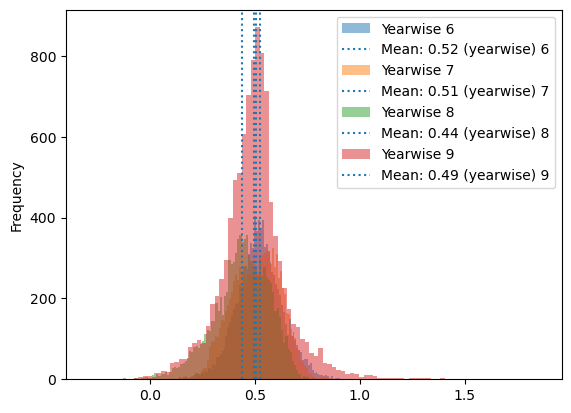

In [13]:
init_mix=[]
init_yearwise=[]
for init in np.unique(target_LP_SON_xr.init_month.values):

    #select values specififc to this init month
    target_LP_SON_xr_init=target_LP_SON_xr.where(target_LP_SON_xr.init_month==init, drop=True)
    drivers_SON_xr_init=drivers_SON_xr.where(drivers_SON_xr.init_month==init, drop=True)

    #first mixing all
    ENSO_precip_LP_SON_tot_init=bootstrap_regression(target_ds=target_LP_SON_xr_init, driver_ds=drivers_SON_xr_init, driver_vars=['ENSO'],
                                            target_var='tp', n_boot=10000, sample_size=200, total_eff=True, add_intercept=True)
    init_mix.append(ENSO_precip_LP_SON_tot_init)
    #now yearwise
    ENSO_precip_LP_SON_tot_yearwise_init=bootstrap_regression(target_ds=target_LP_SON_xr_init, driver_ds=drivers_SON_xr_init, driver_vars=['ENSO'],
                                            target_var='tp', n_boot=10000, sample_size=8, total_eff=True, yearwise=True, add_intercept=True)

    init_yearwise.append(ENSO_precip_LP_SON_tot_yearwise_init)

    scatter_hist_visual(coef_array=ENSO_precip_LP_SON_tot_init, target_ds=target_LP_SON_xr_init['tp'], 
                    driver_ds=drivers_SON_xr_init['ENSO'], driver='ENSO', 
                    suptitle=f'ENSO-->Precip SON sample visual Init {init} (all mixed bootstrap)')

    scatter_hist_visual(coef_array=ENSO_precip_LP_SON_tot_yearwise_init, target_ds=target_LP_SON_xr_init['tp'], 
                    driver_ds=drivers_SON_xr_init['ENSO'], driver='ENSO', 
                    suptitle=f'ENSO-->Precip SON sample visual Init {init} (yearwise bootstrap)')

inits=list(np.unique(target_LP_SON_xr.init_month.values))

for i, element in enumerate(init_mix):
    element['coef_ENSO'].plot.hist(alpha=0.5, label=f'All mixed {inits[i]}', bins=100)
    mean_all=np.mean(element['coef_ENSO'])
    plt.axvline(mean_all, linestyle='dotted',
                    label=f'Mean: {mean_all:.2f} (all mixed) {inits[i]}')
plt.legend()
plt.show()

for i, element in enumerate(init_yearwise):
    element['coef_ENSO'].plot.hist(alpha=0.5, label=f'Yearwise {inits[i]}', bins=100)
    mean=np.mean(element['coef_ENSO'])
    plt.axvline(mean, linestyle='dotted', 
                label=f'Mean: {mean:.2f} (yearwise) {inits[i]}')
plt.legend()
plt.show()

ENSO & A-SAM visual

dict_keys([np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2020), np.int64(2021), np.int64(2022)])
dict_keys([np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), n

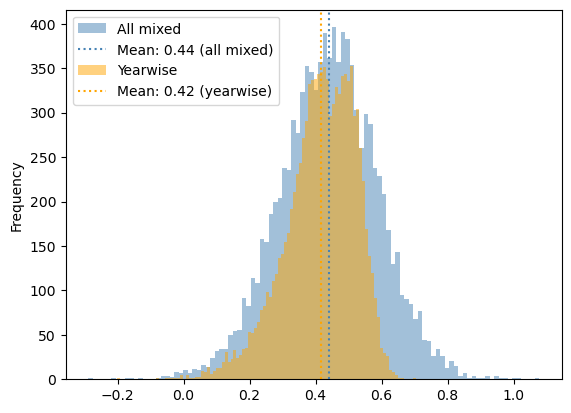

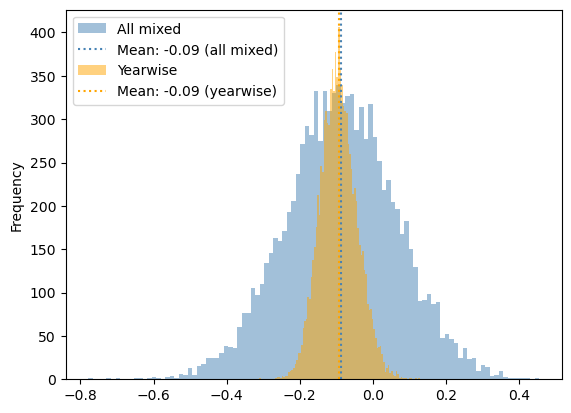

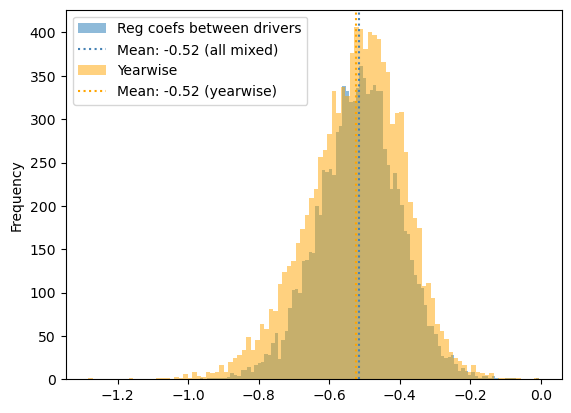

In [14]:
#first mixing all
ENSO_A_SAM_precip_LP_SON_tot=bootstrap_regression(target_ds=target_LP_SON_xr, driver_ds=drivers_SON_xr, driver_vars=['ENSO', 'A_SAM'],
                                            target_var='tp', n_boot=10000, sample_size=200, add_intercept=True)

#now yearwise
ENSO_A_SAM_precip_LP_SON_tot_yearwise=bootstrap_regression(target_ds=target_LP_SON_xr, driver_ds=drivers_SON_xr, driver_vars=['ENSO', 'A_SAM'],
                                            target_var='tp', n_boot=10000, sample_size=8, yearwise=True, add_intercept=True)

ENSO_A_SAM_SON_relationship=bootstrap_regression(target_ds=drivers_SON_xr, driver_ds=drivers_SON_xr, driver_vars=['ENSO'], target_var='A_SAM',
                                                 n_boot=10000, sample_size=200, add_intercept=True)
ENSO_A_SAM_SON_relationship_yearwise=bootstrap_regression(target_ds=drivers_SON_xr, driver_ds=drivers_SON_xr, driver_vars=['ENSO'], target_var='A_SAM',
                                                 n_boot=10000, sample_size=8, yearwise=True,  add_intercept=True)

for driver in ['ENSO', 'A_SAM']:
    ENSO_A_SAM_precip_LP_SON_tot[f'coef_{driver}'].plot.hist(alpha=0.5, label='All mixed', color='steelblue', bins=100)
    mean_all=np.mean(ENSO_A_SAM_precip_LP_SON_tot[f'coef_{driver}'])
    plt.axvline(mean_all, linestyle='dotted', color='steelblue',
                label=f'Mean: {mean_all:.2f} (all mixed)')
    ENSO_A_SAM_precip_LP_SON_tot_yearwise[f'coef_{driver}'].plot.hist(alpha=0.5, color='orange', label='Yearwise', bins=100)
    mean=np.mean(ENSO_A_SAM_precip_LP_SON_tot_yearwise[f'coef_{driver}'])
    plt.axvline(mean, linestyle='dotted', 
                label=f'Mean: {mean:.2f} (yearwise)', color='orange')
    plt.legend()
    plt.show()

ENSO_A_SAM_SON_relationship['coef_ENSO'].plot.hist(alpha=.5, label='Reg coefs between drivers', bins=100)
mean_all=np.mean(ENSO_A_SAM_SON_relationship[f'coef_ENSO'])
plt.axvline(mean_all, linestyle='dotted', color='steelblue',
                label=f'Mean: {mean_all:.2f} (all mixed)')
ENSO_A_SAM_SON_relationship_yearwise[f'coef_ENSO'].plot.hist(alpha=0.5, color='orange', label='Yearwise', bins=100)
mean=np.mean(ENSO_A_SAM_SON_relationship_yearwise[f'coef_ENSO'])
plt.axvline(mean, linestyle='dotted', 
                label=f'Mean: {mean:.2f} (yearwise)', color='orange')
plt.legend()
plt.show()


In [24]:
#added IOD
#first mixing all
ENSO_A_SAM_IOD_precip_LP_SON_tot=bootstrap_regression(target_ds=target_LP_SON_xr, driver_ds=drivers_SON_xr, driver_vars=['ENSO','IOD', 'A_SAM'],
                                            target_var='tp', n_boot=10000, sample_size=200, add_intercept=True)

ENSO_IOD_A_SAM_SON_relationship=bootstrap_regression(target_ds=drivers_SON_xr, driver_ds=drivers_SON_xr, driver_vars=['ENSO', 'IOD'], target_var='A_SAM',
                                                 n_boot=10000, sample_size=200, add_intercept=True)

ENSO_IOD_relationship=bootstrap_regression(target_ds=drivers_SON_xr, driver_ds=drivers_SON_xr, target_var='IOD',
                                           driver_vars=['ENSO'], n_boot=10000, sample_size=200, add_intercept=True)

[0.26645599 0.62948998 0.46663286 ... 0.48612243 0.41844756 0.20087007]


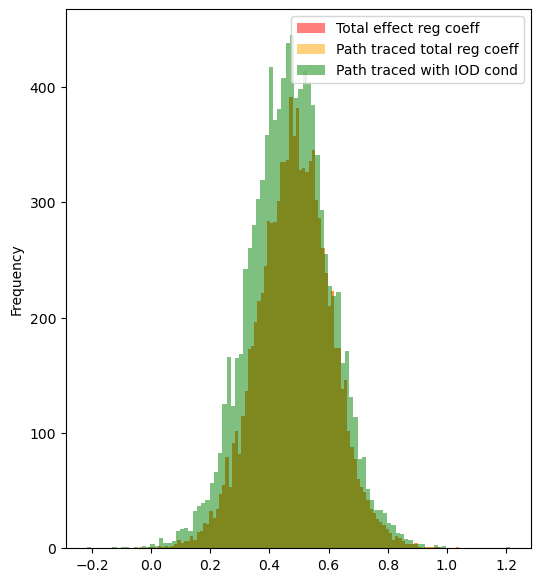

In [30]:
path_tracing=ENSO_A_SAM_SON_relationship['coef_ENSO'].values*ENSO_A_SAM_precip_LP_SON_tot['coef_A_SAM'].dropna().values+\
            ENSO_A_SAM_precip_LP_SON_tot['coef_ENSO'].dropna().values

path_tracing_with_IOD=ENSO_A_SAM_IOD_precip_LP_SON_tot['coef_ENSO'].dropna().values+\
                        ENSO_A_SAM_IOD_precip_LP_SON_tot['coef_A_SAM'].dropna().values*(ENSO_IOD_A_SAM_SON_relationship['coef_ENSO'].dropna().values ) #\
                                                                                       # +ENSO_IOD_A_SAM_SON_relationship['coef_IOD'].dropna().values*ENSO_IOD_relationship['coef_ENSO'].values)\
                                                                                       #+ENSO_A_SAM_IOD_precip_LP_SON_tot['coef_IOD'].dropna().values*ENSO_IOD_relationship['coef_ENSO'].values

print(path_tracing_with_IOD)

fig = plt.figure(figsize=(6,7))
ENSO_precip_LP_SON_tot['coef_ENSO'].plot.hist(alpha=.5, color='red', label='Total effect reg coeff', bins=100)
plt.hist(path_tracing, alpha=.5, color='orange', label='Path traced total reg coeff', bins=100)
plt.hist(path_tracing_with_IOD, alpha=.5, color='green', label='Path traced with IOD cond', bins=100)
plt.legend()


In [16]:
def residualize_array(y, predictors):
    """Regress y on predictors plus an intercept and return residuals."""
    if predictors.shape[1] == 0:
        return y.copy()

    Z = np.column_stack([np.ones(len(y)), predictors])
    beta, *_ = np.linalg.lstsq(Z, y, rcond=None)
    return y - Z @ beta


def scatter_hist_visual(
    coef_array,
    target_ds,
    driver_ds,
    suptitle,
    driver,
    n=5,
    control_drivers=None,
):
    """
    Plot bootstrap samples selected by evenly spaced coefficient values.

    Parameters
    ----------
    coef_array : pandas.DataFrame
        Bootstrap regression results, including coef_<driver> and Index.
    target_ds : xarray.DataArray
        Target variable, with a sample dimension and a number coordinate.
    driver_ds : xarray.Dataset
        Dataset containing the focal driver and any control drivers.
    suptitle : str
        Figure title.
    driver : str
        Focal driver to visualise.
    n : int
        Number of bootstrap samples to plot.
    control_drivers : list[str] or None
        Other drivers to regress out. If None, use all variables in
        driver_ds except the focal driver.
    """

    coef_col = f"coef_{driver}"

    if driver not in driver_ds.data_vars:
        raise ValueError(f"{driver!r} is not a variable in driver_ds.")

    if control_drivers is None:
        control_drivers = [
            name for name in driver_ds.data_vars if name != driver
        ]

    if driver in control_drivers:
        raise ValueError("The focal driver cannot also be a control driver.")

    missing = [v for v in control_drivers if v not in driver_ds.data_vars]
    if missing:
        raise ValueError(f"Missing control drivers: {missing}")

    # Pick bootstrap replicates nearest to evenly spaced coefficient values.
    coef_values = coef_array[coef_col].to_numpy(dtype=float)
    finite_rows = np.flatnonzero(np.isfinite(coef_values))

    if len(finite_rows) == 0:
        raise ValueError(f"No finite values found in {coef_col}.")

    equal_spacing = np.linspace(
        coef_values[finite_rows].min(),
        coef_values[finite_rows].max(),
        n,
    )

    selected_rows = []
    for value in equal_spacing:
        row_idx = finite_rows[
            np.argmin(np.abs(coef_values[finite_rows] - value))
        ]
        selected_rows.append(row_idx)

    fsize = 14
    colors = cm.rainbow(np.linspace(0, 1, n))

    fig, ax = plt.subplots(1, 3, figsize=(21, 6))
    handles = []
    labels = []

    # Apply the same ensemble-member filter used by the bootstrap function.
    members = np.sort(np.unique(target_ds.number.values))
    members_mask = members[:25]

    target_plot = target_ds.where(
        target_ds.number.isin(members_mask), drop=True
    )
    drivers_plot = driver_ds.where(
        driver_ds.number.isin(members_mask), drop=True
    )

    for i, row_idx in enumerate(selected_rows):
        selected = coef_array.iloc[row_idx]
        sample_indices = np.asarray(selected["Index"], dtype=int)

        target_sel = target_plot.isel(sample=sample_indices)
        drivers_sel = drivers_plot.isel(sample=sample_indices)

        y = np.asarray(target_sel.values).ravel()
        x = np.asarray(drivers_sel[driver].values).ravel()

        if control_drivers:
            controls = np.column_stack([
                np.asarray(drivers_sel[name].values).ravel()
                for name in control_drivers
            ])
        else:
            controls = np.empty((len(y), 0))

        # Use the same observations for the target, focal driver and controls.
        valid = (
            np.isfinite(y)
            & np.isfinite(x)
            & np.all(np.isfinite(controls), axis=1)
        )

        y = y[valid]
        x = x[valid]
        controls = controls[valid]

        if len(y) < 3:
            continue

        # Partial regression: remove the other drivers from BOTH variables.
        if control_drivers:
            y_plot = residualize_array(y, controls)
            x_plot = residualize_array(x, controls)

            # Frisch-Waugh-Lovell slope: regression through the origin.
            denom = np.dot(x_plot, x_plot)
            if denom <= np.finfo(float).eps:
                continue

            slope = np.dot(x_plot, y_plot) / denom
            x_line = np.linspace(x_plot.min(), x_plot.max(), 100)
            y_line = slope * x_line

            x_label = f"{driver} residualised against controls"
            y_label = "Target residualised against controls"

        else:
            # With no controls, plot the original data and fit an intercept.
            x_plot = x
            y_plot = y

            Xreg = np.column_stack([np.ones(len(x_plot)), x_plot])
            beta, *_ = np.linalg.lstsq(Xreg, y_plot, rcond=None)
            slope = beta[1]

            x_line = np.linspace(x_plot.min(), x_plot.max(), 100)
            y_line = beta[0] + slope * x_line

            x_label = f"Driver {driver}"
            y_label = "Target"

        # Scatter and regression line.
        ax[0].scatter(
            x_plot, y_plot, color=colors[i], alpha=0.35, s=18
        )
        ax[0].plot(
            x_line,
            y_line,
            color=colors[i],
            linewidth=2,
        )

        # PCA-oriented ellipse, expanded to contain every plotted point.
        points = np.column_stack([x_plot, y_plot])
        center = points.mean(axis=0)
        centered = points - center

        _, eigenvectors = np.linalg.eigh(np.cov(centered, rowvar=False))
        eigenvectors = eigenvectors[:, ::-1]
        projected = centered @ eigenvectors

        a = np.max(np.abs(projected[:, 0]))
        b = np.max(np.abs(projected[:, 1]))

        if a > 0 and b > 0:
            radii = np.sqrt(
                (projected[:, 0] / a) ** 2
                + (projected[:, 1] / b) ** 2
            )
            scale = max(1.0, np.max(radii)) * 1.03

            angle = np.degrees(
                np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
            )

            ellipse = Ellipse(
                xy=center,
                width=2 * a * scale,
                height=2 * b * scale,
                angle=angle,
                facecolor=colors[i],
                edgecolor=colors[i],
                alpha=0.15,
                linewidth=1.5,
            )
            ax[0].add_patch(ellipse)

        handles.append(
            plt.Line2D([0], [0], color=colors[i], linewidth=2)
        )
        labels.append(f"β = {selected[coef_col]:.2f}")

        # Histograms show the same data used in the scatter plot.
        ax[1].hist(
            y_plot, bins=15, color=colors[i], alpha=0.25,
            histtype="step", linewidth=2
        )
        ax[2].hist(
            x_plot, bins=15, color=colors[i], alpha=0.25,
            histtype="step", linewidth=2
        )

    ax[0].set_xlabel(x_label, fontsize=fsize)
    ax[0].set_ylabel(y_label, fontsize=fsize)
    ax[0].axhline(0, color="grey", linewidth=0.8)
    ax[0].axvline(0, color="grey", linewidth=0.8)
    ax[0].grid(alpha=0.3)

    ax[1].set_xlabel(y_label, fontsize=fsize)
    ax[1].set_ylabel("Count", fontsize=fsize)

    ax[2].set_xlabel(x_label, fontsize=fsize)
    ax[2].set_ylabel("Count", fontsize=fsize)

    for axis in ax:
        axis.tick_params(labelsize=fsize)

    if handles:
        fig.legend(
            handles,
            labels,
            ncols=min(n, len(handles)),
            bbox_to_anchor=(0.5, -0.03),
            loc="lower center",
            fontsize=fsize,
        )

    fig.suptitle(suptitle, fontweight="bold", fontsize=fsize + 2)
    fig.tight_layout(rect=[0, 0.08, 1, 0.93])
    plt.show()

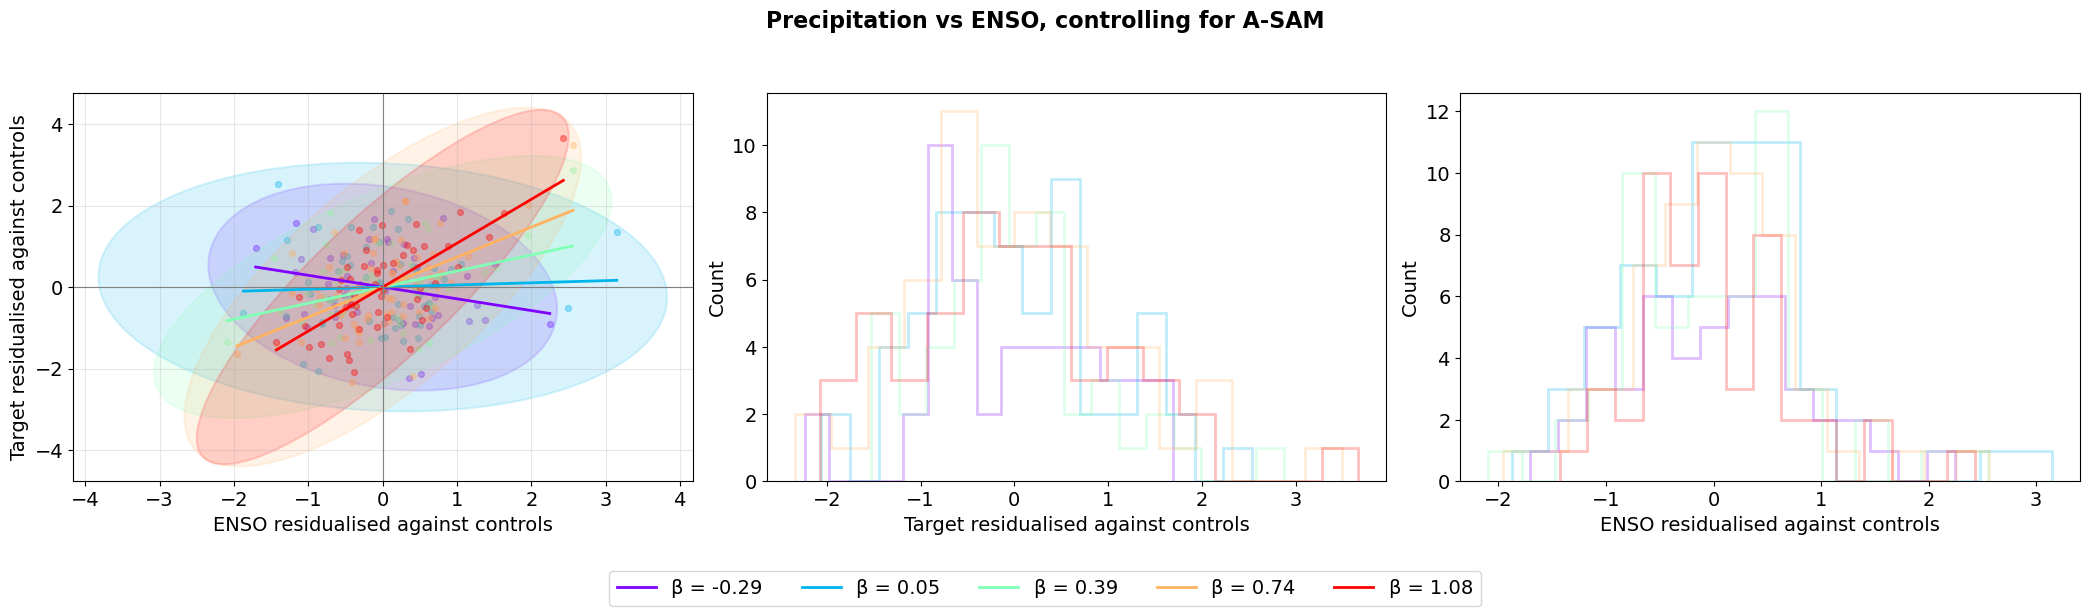

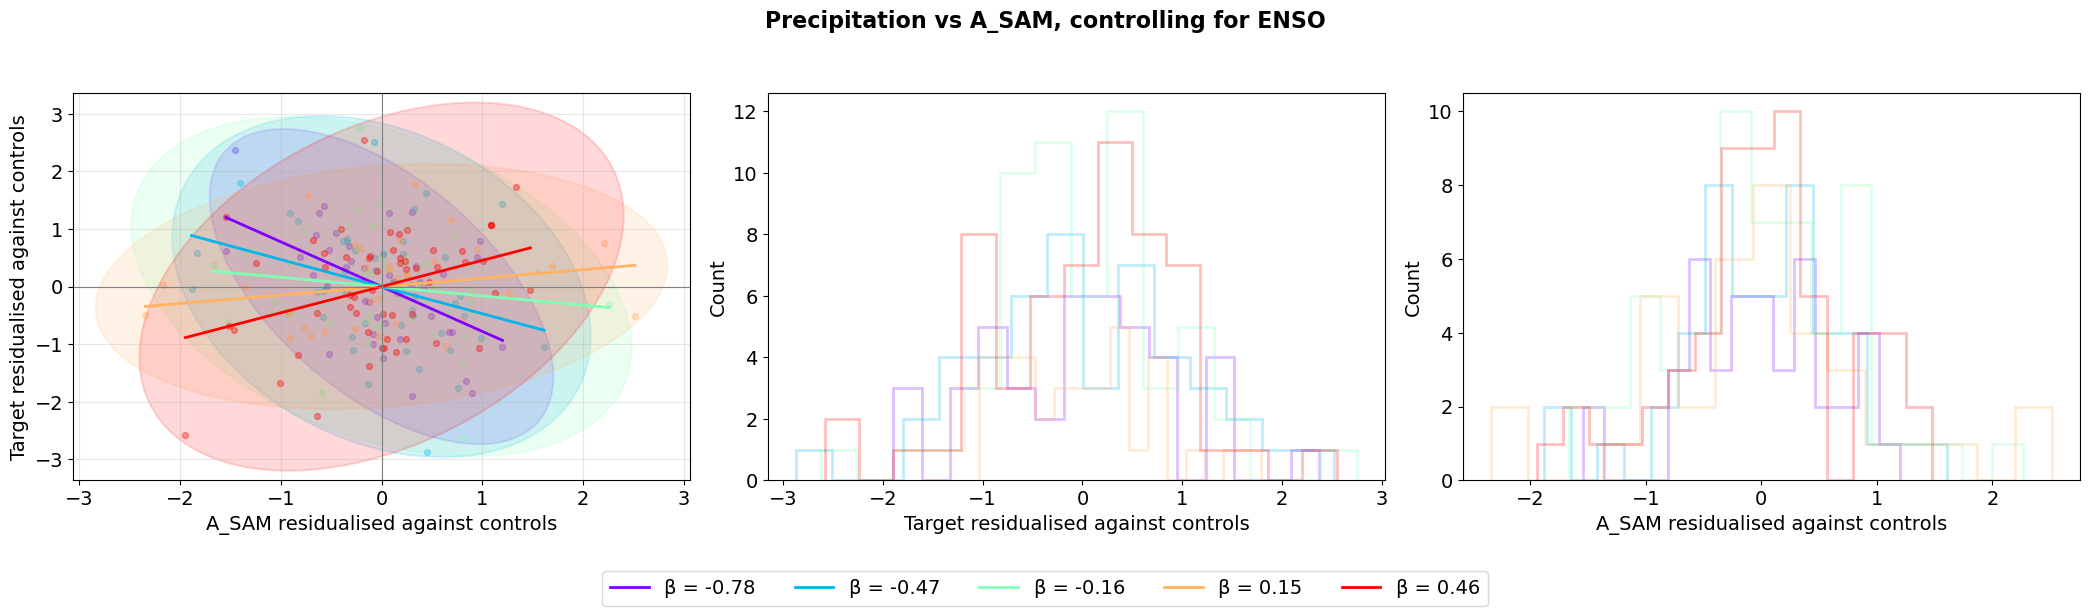

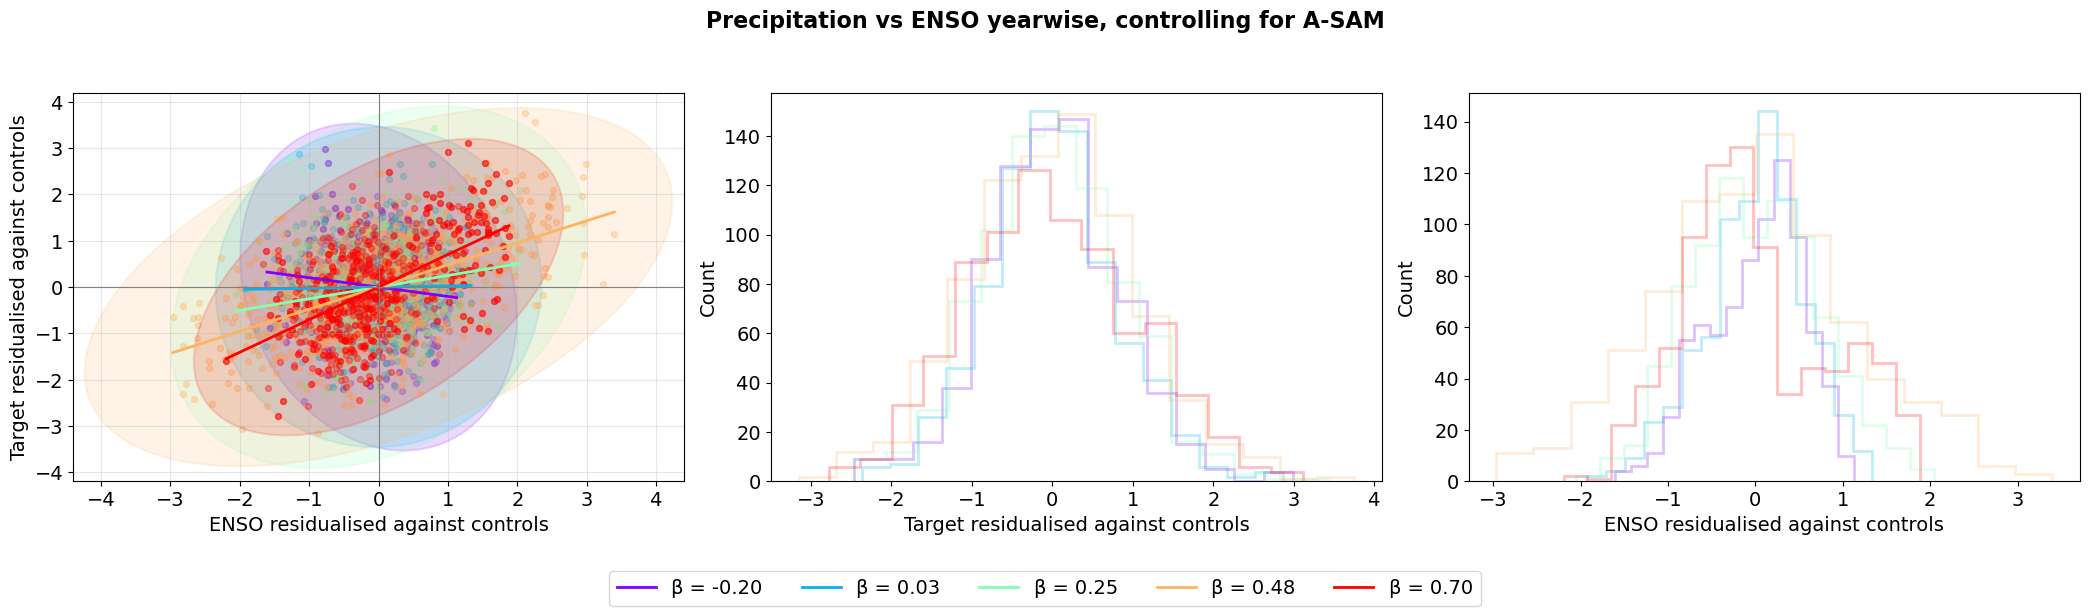

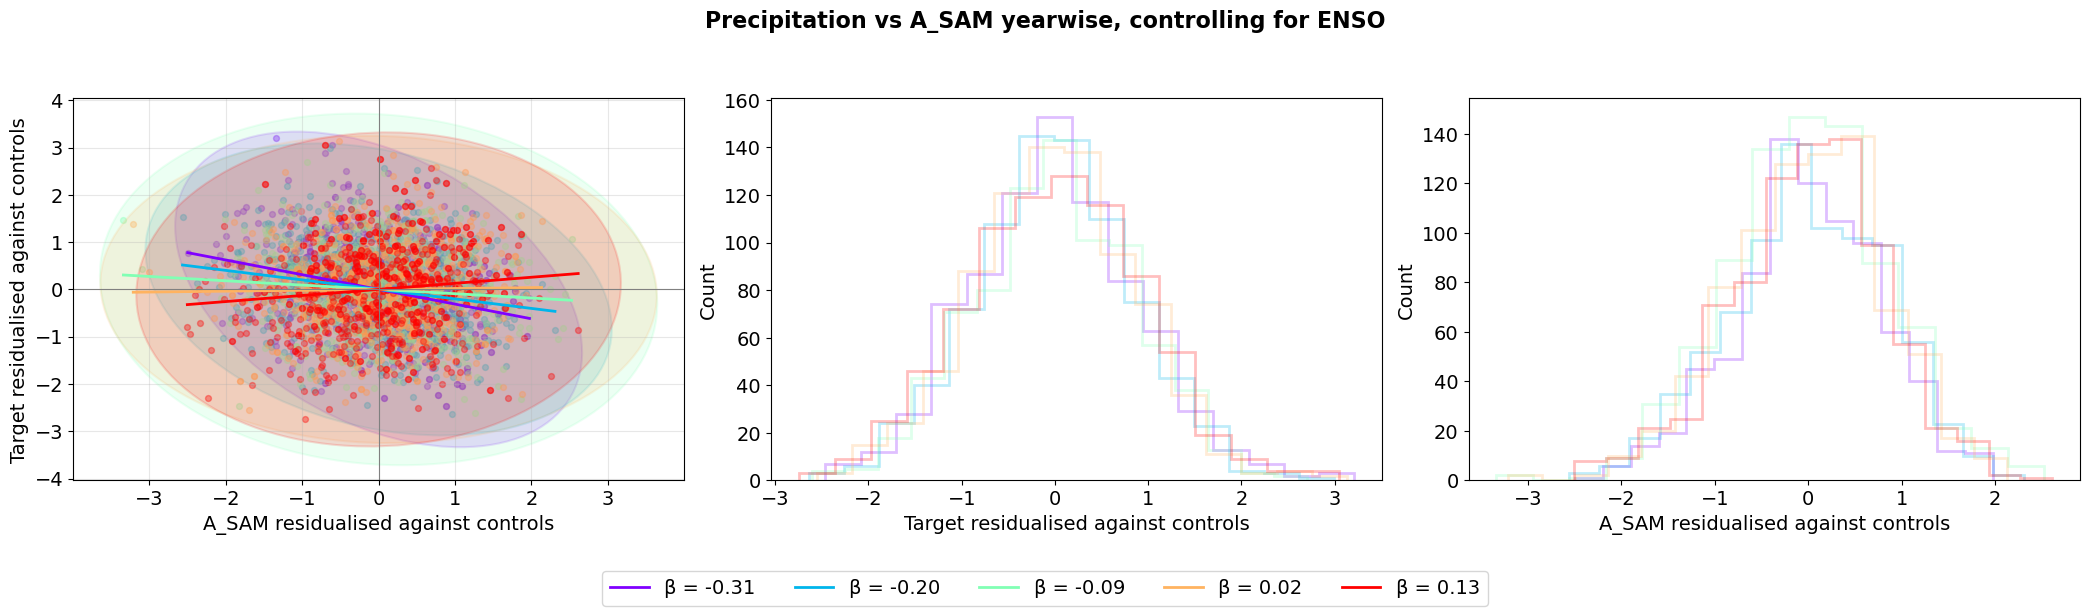

In [17]:
scatter_hist_visual(
    coef_array=ENSO_A_SAM_precip_LP_SON_tot,
    target_ds=target_LP_SON_xr["tp"],
    driver_ds=drivers_SON_xr,
    suptitle="Precipitation vs ENSO, controlling for A-SAM",
    driver="ENSO",
    control_drivers=["A_SAM"],
    n=5,
)

scatter_hist_visual(
    coef_array=ENSO_A_SAM_precip_LP_SON_tot,
    target_ds=target_LP_SON_xr["tp"],
    driver_ds=drivers_SON_xr,
    suptitle="Precipitation vs A_SAM, controlling for ENSO",
    driver="A_SAM",
    control_drivers=["ENSO"],
    n=5,
)

scatter_hist_visual(
    coef_array=ENSO_A_SAM_precip_LP_SON_tot_yearwise,
    target_ds=target_LP_SON_xr["tp"],
    driver_ds=drivers_SON_xr,
    suptitle="Precipitation vs ENSO yearwise, controlling for A-SAM",
    driver="ENSO",
    control_drivers=["A_SAM"],
    n=5,
)

scatter_hist_visual(
    coef_array=ENSO_A_SAM_precip_LP_SON_tot_yearwise,
    target_ds=target_LP_SON_xr["tp"],
    driver_ds=drivers_SON_xr,
    suptitle="Precipitation vs A_SAM yearwise, controlling for ENSO",
    driver="A_SAM",
    control_drivers=["ENSO"],
    n=5,
)